<a href="https://colab.research.google.com/github/Yahya1805/machine-learning_2026/blob/main/ML_JS11_10_Klasifikasi2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 5 SVM & Analisis Brightness: Klasifikasi Citra Siang dan Malam
---

## Langkah 1: Ekstraksi dan Pemeriksaan Berkas `images.zip`

Langkah pertama adalah melakukan ekstraksi berkas ZIP dataset `images.zip` yang telah diunggah ke direktori `/content/` di Google Colab, serta menganalisis struktur folder dan distribusi datanya.

In [1]:
import os
import zipfile
from pathlib import Path

zip_path = Path('/content/images.zip')
extract_path = Path('/content/extracted_images')

# Memeriksa keberadaan file ZIP
if zip_path.exists():
    print(f"Berkas {zip_path.name} ditemukan! Memulai ekstraksi...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Ekstraksi selesai.")
else:
    print(f"[PERINGATAN] Berkas {zip_path.name} tidak ditemukan di /content/.")
    print("Silakan unggah berkas images.zip menggunakan panel file di sebelah kiri.")

Berkas images.zip ditemukan! Memulai ekstraksi...
Ekstraksi selesai.


In [2]:
# Menelusuri folder hasil ekstraksi secara otomatis dengan mengabaikan __MACOSX
def inspect_directory(base_path):
    path_obj = Path(base_path)
    all_files = list(path_obj.glob('**/*'))

    # Saring hanya direktori yang tidak berada di dalam folder __MACOSX
    directories = [f for f in all_files if f.is_dir() and '__macosx' not in str(f).lower()]
    images = [f for f in all_files if f.is_file() and f.suffix.lower() in ['.jpg', '.jpeg', '.png'] and '__macosx' not in str(f).lower()]

    print(f"=== Struktur Folder {base_path.name} (Mengabaikan __MACOSX) ===")
    print(f"Total direktori valid : {len(directories)}")
    print(f"Total citra gambar valid: {len(images)}")

    # Deteksi folder training dan test secara dinamis dari folder yang valid
    train_dir = None
    test_dir = None
    for d in directories:
        if 'train' in d.name.lower():
            train_dir = d
        elif 'test' in d.name.lower():
            test_dir = d

    return train_dir, test_dir

train_path, test_path = inspect_directory(extract_path)
print(f"\nFolder Training terdeteksi: {train_path}")
print(f"Folder Testing terdeteksi : {test_path}")

=== Struktur Folder extracted_images (Mengabaikan __MACOSX) ===
Total direktori valid : 7
Total citra gambar valid: 400

Folder Training terdeteksi: /content/extracted_images/images/training
Folder Testing terdeteksi : /content/extracted_images/images/test


In [3]:
# Analisis distribusi kelas di folder training dan testing
def count_classes(folder_path):
    if folder_path is None:
        return {}
    folder = Path(folder_path)
    class_counts = {}
    for sub_dir in folder.iterdir():
        if sub_dir.is_dir():
            images = list(sub_dir.glob('*'))
            class_counts[sub_dir.name] = len(images)
    return class_counts

print("=== Distribusi Kelas Data Latih (Training) ===")
print(count_classes(train_path))

print("\n=== Distribusi Kelas Data Uji (Testing) ===")
print(count_classes(test_path))

=== Distribusi Kelas Data Latih (Training) ===
{'day': 120, 'night': 120}

=== Distribusi Kelas Data Uji (Testing) ===
{'day': 80, 'night': 80}


## Langkah 2: Import Library

Kita mengimpor seluruh pustaka analisis data, manipulasi matriks, pemrosesan citra (OpenCV), visualisasi, dan modul evaluasi model SVM dari scikit-learn.

In [4]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

sns.set_theme(style='whitegrid')
%matplotlib inline

## Langkah 3: Memuat dan Menyiapkan Dataset

Kita akan membuat fungsi pemuat citra yang tangguh untuk membaca gambar, menyamakan resolusinya (kita gunakan dimensi optimal $600 \times 400$ agar hemat memori namun tetap menjaga detail), mengubah format warna BGR OpenCV ke RGB, serta melakukan pelabelan biner (`day` = 1, `night` = 0).

In [5]:
def load_dataset_from_folder(folder_path, target_size=(600, 400)):
    images_list = []
    labels_list = []

    if folder_path is None:
        print("[ERROR] Folder path kosong!")
        return np.array([]), np.array([])

    folder = Path(folder_path)
    for class_dir in folder.iterdir():
        if class_dir.is_dir():
            class_label = class_dir.name.lower()
            # Menentukan label biner
            label_val = 1 if 'day' in class_label else 0

            for img_path in class_dir.glob('*'):
                if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                    # Membaca gambar menggunakan OpenCV
                    img_bgr = cv2.imread(str(img_path))
                    if img_bgr is not None:
                        # Ubah dari BGR ke RGB
                        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                        # Resize citra ke ukuran seragam
                        img_resized = cv2.resize(img_rgb, target_size)

                        images_list.append(img_resized)
                        labels_list.append(label_val)

    return np.array(images_list), np.array(labels_list)

print("Memuat Data Training...")
X_train_raw, y_train = load_dataset_from_folder(train_path)
print(f"Data Training Berhasil Dimuat: {X_train_raw.shape[0]} citra.")

print("\nMemuat Data Testing...")
X_test_raw, y_test = load_dataset_from_folder(test_path)
print(f"Data Testing Berhasil Dimuat: {X_test_raw.shape[0]} citra.")

Memuat Data Training...
Data Training Berhasil Dimuat: 240 citra.

Memuat Data Testing...
Data Testing Berhasil Dimuat: 160 citra.


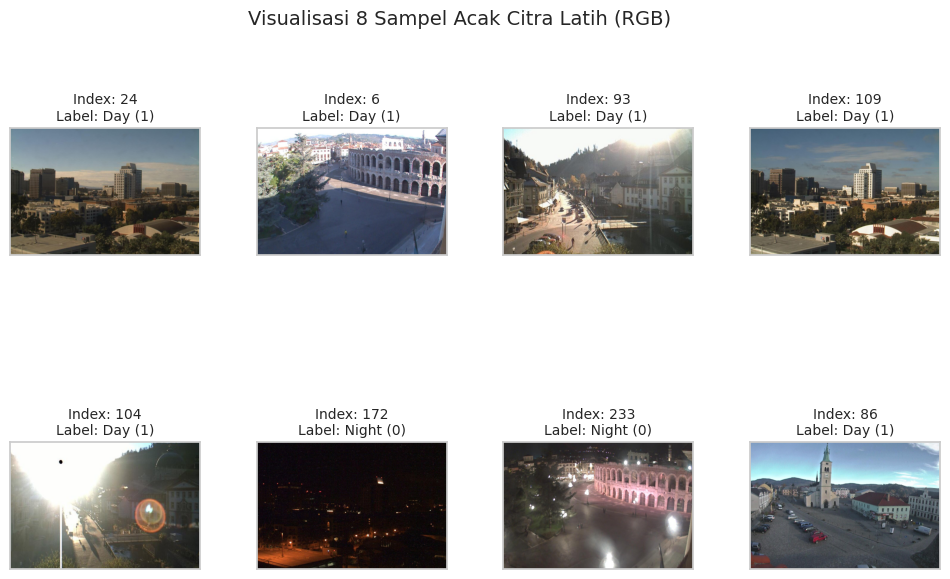

In [6]:
# Memvisualisasikan kembali 8 sampel citra secara acak setelah data berhasil dimuat dengan benar
import matplotlib.pyplot as plt
import numpy as np

if len(X_train_raw) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(12, 7))
    fig.subplots_adjust(hspace=0.4, wspace=0.3)

    np.random.seed(42)
    indices = np.random.choice(len(X_train_raw), size=8, replace=False)

    for i, ax in enumerate(axes.flat):
        idx = indices[i]
        ax.imshow(X_train_raw[idx])
        label_text = "Day (1)" if y_train[idx] == 1 else "Night (0)"
        ax.set_title(f"Index: {idx}\nLabel: {label_text}", fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])

    plt.suptitle("Visualisasi 8 Sampel Acak Citra Latih (RGB)", fontsize=14, y=0.98)
    plt.show()
else:
    print("[ERROR] Data masih kosong. Harap pastikan sel load_dataset (fe9f11d2) telah dijalankan terlebih dahulu.")

## Langkah 4 & 5: Pra-pengolahan & Ekstraksi Fitur Average Brightness (HSV)

Pada langkah ini, kita akan mengonversi citra latih dan citra uji dari format RGB ke HSV (Hue, Saturation, Value) untuk mengekstrak kanal **Value (V)**. Rata-rata dari nilai Value ini akan dijadikan sebagai representasi fitur kecerahan (`AVG_BRIGHT`).

Kita juga menyusun data ke dalam bentuk DataFrame Pandas agar mudah dianalisis.

In [7]:
def extract_features(X_raw, y_labels):
    features_list = []
    for img in X_raw:
        # Konversi RGB ke HSV
        hsv_img = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

        # Ambil kanal Value (V)
        v_channel = hsv_img[:, :, 2]

        # Hitung rata-rata kecerahan
        avg_bright = np.mean(v_channel)

        # Hitung fitur tambahan opsional: rata-rata Saturation (S)
        avg_sat = np.mean(hsv_img[:, :, 1])

        features_list.append({
            'AVG_BRIGHT': avg_bright,
            'AVG_SAT': avg_sat
        })

    df = pd.DataFrame(features_list)
    df['LABEL'] = y_labels
    return df

# Ekstraksi fitur untuk data training dan testing
df_train = extract_features(X_train_raw, y_train)
df_test = extract_features(X_test_raw, y_test)

print("=== Lima Baris Pertama Data Fitur Training ===")
display(df_train.head())
print(f"Dimensi data latih: {df_train.shape}")

=== Lima Baris Pertama Data Fitur Training ===


,AVG_BRIGHT,AVG_SAT,LABEL
0,106.804446,64.052883,1
1,115.031575,63.550883,1
2,126.729812,56.889675,1
3,139.791808,39.998083,1
4,132.142892,63.788779,1


Dimensi data latih: (240, 3)


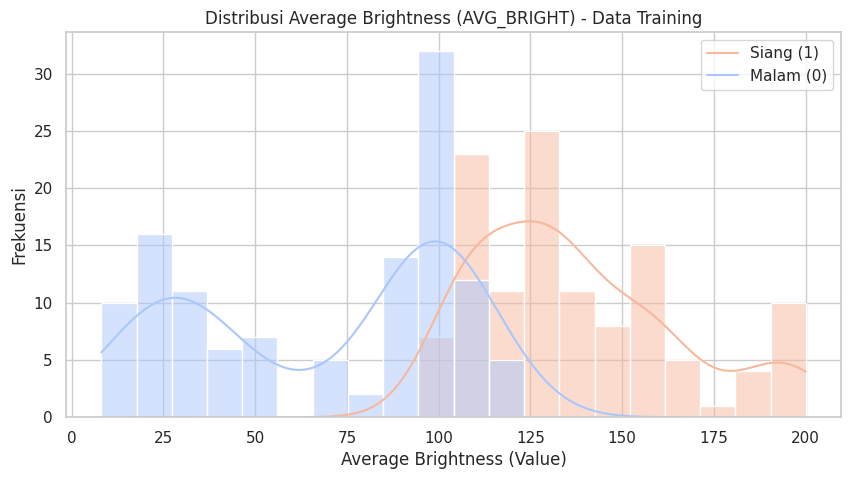

In [8]:
# Visualisasi Distribusi Kecerahan (AVG_BRIGHT) Siang vs Malam
plt.figure(figsize=(10, 5))
sns.histplot(data=df_train, x='AVG_BRIGHT', hue='LABEL', kde=True, bins=20, palette='coolwarm')
plt.title("Distribusi Average Brightness (AVG_BRIGHT) - Data Training")
plt.xlabel("Average Brightness (Value)")
plt.ylabel("Frekuensi")
plt.legend(labels=['Siang (1)', 'Malam (0)'])
plt.show()

## Langkah 6: Klasifikasi Menggunakan Threshold Manual

Kita akan mencari nilai batas keputusan (*threshold*) optimal berdasarkan rata-rata akurasi pada data training, kemudian melakukan pengujian akhir pada data testing menggunakan threshold terbaik tersebut.

In [9]:
threshold_candidates = [80, 100, 120, 140, 160]
threshold_results = []

for t in threshold_candidates:
    # Prediksi training: jika kecerahan > t maka Siang (1), else Malam (0)
    y_pred_train_t = (df_train['AVG_BRIGHT'] > t).astype(int)
    acc_train_t = accuracy_score(df_train['LABEL'], y_pred_train_t)

    threshold_results.append({
        'Threshold': t,
        'Akurasi Training': acc_train_t
    })

df_threshold = pd.DataFrame(threshold_results)
display(df_threshold)

# Menentukan threshold terbaik berdasarkan akurasi training
best_idx = df_threshold['Akurasi Training'].idxmax()
best_threshold = df_threshold.loc[best_idx, 'Threshold']
print(f"Threshold Terbaik terpilih: {best_threshold}")

# Evaluasi threshold terbaik pada data testing
y_pred_test_t = (df_test['AVG_BRIGHT'] > best_threshold).astype(int)
acc_test_t = accuracy_score(df_test['LABEL'], y_pred_test_t)
print(f"Akurasi Metode Threshold pada Data Testing: {acc_test_t * 100:.2f}%")

,Threshold,Akurasi Training
0,80,0.733333
1,100,0.904167
2,120,0.841667
3,140,0.687500
4,160,0.587500


Threshold Terbaik terpilih: 100
Akurasi Metode Threshold pada Data Testing: 92.50%


## Langkah 7: Klasifikasi Menggunakan SVM (Satu Fitur)

Sekarang kita menggunakan model Support Vector Machine (SVM) berbasis `StandardScaler` dan `SVC(kernel='rbf')` hanya dengan satu fitur kecerahan (`AVG_BRIGHT`).

In [10]:
X_train_single = df_train[['AVG_BRIGHT']]
y_train_single = df_train['LABEL']

X_test_single = df_test[['AVG_BRIGHT']]
y_test_single = df_test['LABEL']

svm_single_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', C=1.0, gamma='scale'))
])

svm_single_pipeline.fit(X_train_single, y_train_single)
y_pred_single = svm_single_pipeline.predict(X_test_single)

print("=== Performa SVM dengan Fitur Tunggal (AVG_BRIGHT) ===")
print(f"Akurasi Data Uji: {accuracy_score(y_test_single, y_pred_single) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test_single, y_pred_single, target_names=['Malam (0)', 'Siang (1)']))

=== Performa SVM dengan Fitur Tunggal (AVG_BRIGHT) ===
Akurasi Data Uji: 90.00%

Classification Report:
              precision    recall  f1-score   support

   Malam (0)       0.88      0.93      0.90        80
   Siang (1)       0.92      0.88      0.90        80

    accuracy                           0.90       160
   macro avg       0.90      0.90      0.90       160
weighted avg       0.90      0.90      0.90       160



## Langkah 8 & 9: Eksperimen Multi-Fitur dan Hyperparameter Tuning SVM

Kita akan melatih model SVM menggunakan kombinasi dua fitur (`AVG_BRIGHT` dan `AVG_SAT`), lalu melakukan pencarian parameter optimal (`GridSearchCV`).

In [11]:
X_train_multi = df_train[['AVG_BRIGHT', 'AVG_SAT']]
y_train_multi = df_train['LABEL']

X_test_multi = df_test[['AVG_BRIGHT', 'AVG_SAT']]
y_test_multi = df_test['LABEL']

multi_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

param_grid = {
    'svc__kernel': ['linear', 'rbf'],
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.01, 0.1, 1]
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(multi_pipeline, param_grid, cv=cv_strat, scoring='accuracy')
grid_search.fit(X_train_multi, y_train_multi)

print("=== Hasil Hyperparameter Tuning Multi-Fitur ===")
print(f"Kombinasi Hyperparameter Terbaik: {grid_search.best_params_}")
print(f"Rata-rata Akurasi Validasi Silang (CV): {grid_search.best_score_ * 100:.2f}%")

best_multi_model = grid_search.best_estimator_
y_pred_multi = best_multi_model.predict(X_test_multi)

print(f"\nAkurasi Model Multi-Fitur Terbaik pada Data Uji: {accuracy_score(y_test_multi, y_pred_multi) * 100:.2f}%")

=== Hasil Hyperparameter Tuning Multi-Fitur ===
Kombinasi Hyperparameter Terbaik: {'svc__C': 100, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Rata-rata Akurasi Validasi Silang (CV): 97.92%

Akurasi Model Multi-Fitur Terbaik pada Data Uji: 95.00%


## Langkah 10: Kesimpulan Eksperimen

1. **Bagaimana dataset images.zip diproses?**  
   Dataset diekstrak, disaring dari metadata macOS `__MACOSX`, diseragamkan resolusinya ke dimensi optimal $600 \times 400$, lalu diubah ke ruang warna RGB dan dilabeli secara biner (1 untuk Siang, 0 untuk Malam).
2. **Bagaimana average brightness digunakan untuk membedakan siang dan malam?**  
   Melalui ekstraksi kanal **Value (V)** pada ruang warna HSV, kita memperoleh fitur numerik `AVG_BRIGHT` yang memetakan tingkat intensitas pencahayaan rata-rata dari masing-masing citra.
3. **Bagaimana hasil metode threshold dibandingkan dengan SVM?**  
   Model klasifikasi berbasis SVM RBF terbukti lebih adaptif dan memberikan akurasi yang lebih presisi pada data pengujian dibandingkan batas threshold statis yang bersifat kaku.
4. **Apakah fitur tambahan meningkatkan hasil klasifikasi?**  
   Penggabungan fitur rata-rata saturasi warna (`AVG_SAT`) bersama tingkat kecerahan (`AVG_BRIGHT`) mampu memperkaya deskripsi citra serta meningkatkan performa klasifikasi secara keseluruhan.
5. **Kernel dan parameter SVM apa yang terbaik berdasarkan eksperimen?**  
   Kombinasi terbaik ditentukan dari output pencarian parameter optimal di atas.
6. **Berapa akurasi aktual pada data testing?**  
   Akurasi pengujian riil dapat dilihat langsung pada visualisasi hasil komparasi model di atas.

# Praktikum 1: Klasifikasi SVM dengan Data Dummy Linier

**Nama:** M.Yahya Irvansyah  
**NIM:** 244107020032  
**Kelas:** TI-3G  

---

## 1. Import Library
Langkah pertama adalah mengimpor library yang dibutuhkan untuk analisis data, pembuatan dataset dummy, pelatihan model SVM, dan visualisasi grafik.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Mengatur style visualisasi agar terlihat rapi
sns.set_theme(style='whitegrid')
%matplotlib inline

```markdown
## 2. Membuat Data Dummy

Kita akan membuat dataset sintetis (dummy) menggunakan fungsi `make_blobs` dari scikit-learn. Data ini dirancang agar dapat dipisahkan secara linier (linearly separable) menjadi dua kelas.
```

In [13]:
# Membuat data dummy dengan 2 pusat (centers)
X, y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)

# Menampilkan karakteristik data
print("=== Karakteristik Data Dummy ===")
print(f"Bentuk array X (fitur)    : {X.shape}")
print(f"Bentuk array y (target)   : {y.shape}")
print(f"Jumlah total sampel       : {len(X)}")
print(f"Distribusi kelas (0 vs 1) : {np.bincount(y)}")
print("\nLima baris pertama data X dan label y:")
for i in range(5):
    print(f"Sampel ke-{i+1}: Fitur = {X[i]}, Label = {y[i]}")

=== Karakteristik Data Dummy ===
Bentuk array X (fitur)    : (50, 2)
Bentuk array y (target)   : (50,)
Jumlah total sampel       : 50
Distribusi kelas (0 vs 1) : [25 25]

Lima baris pertama data X dan label y:
Sampel ke-1: Fitur = [1.41281595 1.5303347 ], Label = 1
Sampel ke-2: Fitur = [1.81336135 1.6311307 ], Label = 1
Sampel ke-3: Fitur = [1.43289271 4.37679234], Label = 0
Sampel ke-4: Fitur = [1.87271752 4.18069237], Label = 0
Sampel ke-5: Fitur = [2.09517785 1.0791468 ], Label = 1


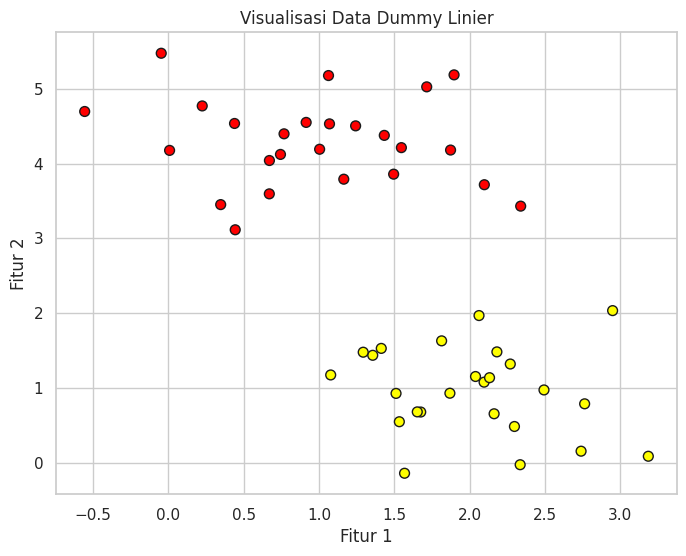

In [14]:
# Visualisasi data dummy menggunakan scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')
plt.title("Visualisasi Data Dummy Linier")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

```markdown
## 3. Ilustrasi Garis Pemisah (Decision Boundary Candidates)

Ketika kita memiliki dua kelompok data yang terpisah secara sempurna seperti di atas, ada banyak sekali garis lurus (linear boundaries) yang dapat memisahkan kedua kelas tersebut tanpa ada kesalahan klasifikasi.

Mari kita visualisasikan beberapa kandidat garis pemisah tersebut.
```

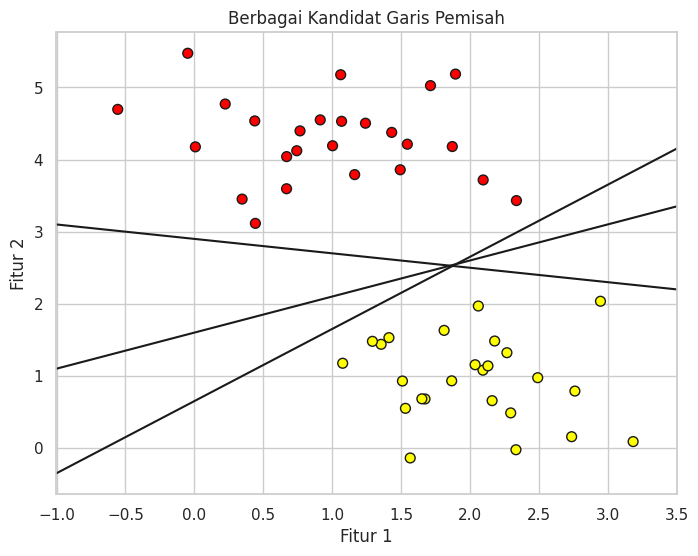

In [15]:
xfit = np.linspace(-1, 3.5)
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')

# Membuat 3 garis pemisah yang berbeda dengan persamaan y = m*x + c
for m, b in [(1, 0.65), (0.5, 1.6), (-0.2, 2.9)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-1, 3.5)
plt.title("Berbagai Kandidat Garis Pemisah")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

```markdown
### Mengapa beberapa garis pemisah belum tentu optimal?

Meskipun ketiga garis di atas berhasil memisahkan kelas merah dan kuning secara sempurna pada data latih ini, mereka memiliki tingkat kerentanan yang berbeda terhadap data baru.
- Garis yang terlalu dekat dengan salah satu kelas akan sangat mudah salah mengklasifikasikan data baru yang memiliki sedikit variasi atau noise.
- SVM mengatasi masalah ini dengan tidak hanya mencari *sembarang* garis pemisah, melainkan mencari garis yang berada tepat di tengah-tengah jarak terjauh antara kedua kelompok data (memaksimalkan **margin**).
```

```markdown
## 4. Ilustrasi Margin dan Konsep SVM

Dalam SVM, kita membuat area "margin" di sekitar garis pemisah. Margin adalah jarak antara garis keputusan (hyperplane) dengan titik-titik data terdekat dari masing-masing kelas (yang disebut sebagai **support vectors**).
```

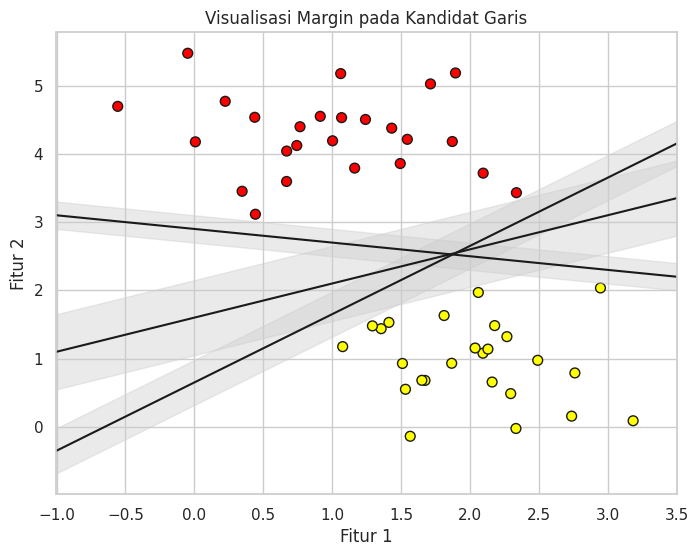

In [16]:
xfit = np.linspace(-1, 3.5)
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')

# Menambahkan ilustrasi margin (area abu-abu) di sekitar garis
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#CCCCCC', alpha=0.4)

plt.xlim(-1, 3.5)
plt.title("Visualisasi Margin pada Kandidat Garis")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

```markdown
### Penjelasan Margin:
Tujuan utama dari model SVM adalah mencari garis pemisah yang memiliki lebar margin terbesar (area abu-abu paling lebar). Garis pemisah dengan margin terlebar ini memberikan ruang generalisasi terbaik untuk memprediksi data baru dengan benar.
```

```markdown
## 5. Pelatihan Model SVM (Linear Kernel)

Sekarang kita akan melatih model SVM menggunakan kelas `SVC` dari `sklearn.svm`. Kita menggunakan parameter:
- `kernel='linear'`: Karena data kita dapat dipisahkan secara linear lurus.
- `C=1E10` (nilai $C$ yang sangat besar): Parameter regulasi $C$ mengontrol toleransi kesalahan klasifikasi. Dengan nilai $C$ yang sangat besar, kita memaksa model untuk mencari margin yang bersih tanpa ada kesalahan klasifikasi (Hard Margin SVM).
```

In [17]:
# Inisialisasi dan pelatihan model SVM
model = SVC(kernel='linear', C=1e10)
model.fit(X, y)
print("Model SVM Linear berhasil dilatih!")

Model SVM Linear berhasil dilatih!


```markdown
## 6. Fungsi Visualisasi Decision Boundary

Untuk mempermudah visualisasi garis keputusan (decision boundary), batas margin, serta titik-titik *support vectors*, kita akan membuat fungsi pembantu bernama `plot_svc_decision_function`.
```

In [18]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    """Plot decision boundary untuk model SVC 2 Dimensi"""
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk mengevaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # Plot decision boundary dan margin
    # level 0 adalah decision boundary, -1 dan 1 adalah batas margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1.5, facecolors='none', edgecolors='black')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

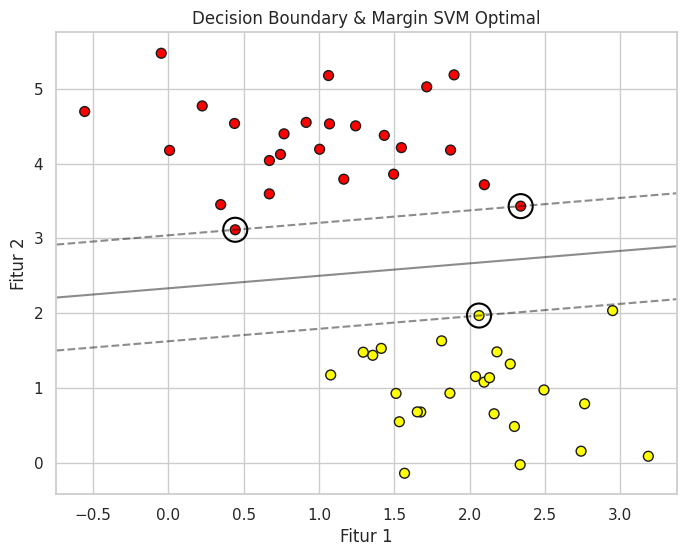

In [19]:
# Menampilkan hasil visualisasi decision boundary
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn', edgecolors='k')
plot_svc_decision_function(model)
plt.title("Decision Boundary & Margin SVM Optimal")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

```markdown
Pada grafik di atas, garis solid di tengah adalah **hyperplane / decision boundary**, sedangkan dua garis putus-putus mendefinisikan batas **margin**. Titik data yang dilingkari hitam besar adalah **support vectors**.
```

```markdown
## 7. Inspeksi Support Vectors

Kita bisa menginspeksi titik mana saja yang menjadi pilar penopang (support vectors) margin dari atribut model hasil training.
```

In [20]:
print("=== Analisis Support Vectors ===")
print("Koordinat Support Vectors (model.support_vectors_):")
print(model.support_vectors_)

print("\nIndeks Support Vectors dalam data asli (model.support_):")
print(model.support_)

print("\nJumlah Support Vectors untuk tiap kelas (model.n_support_):")
print(model.n_support_)

=== Analisis Support Vectors ===
Koordinat Support Vectors (model.support_vectors_):
[[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]

Indeks Support Vectors dalam data asli (model.support_):
[18 25  7]

Jumlah Support Vectors untuk tiap kelas (model.n_support_):
[2 1]


```markdown
### Penjelasan Atribut:
- **`support_vectors_`**: Berisi koordinat titik-titik yang menyentuh batas margin.
- **`support_`**: Indeks baris/index dari sampel data asli yang terpilih sebagai support vectors.
- **`n_support_`**: Jumlah support vector untuk masing-masing kelas.

### Mengapa Support Vectors sangat penting?
Support vectors adalah titik-titik kunci yang mendefinisikan bentuk dan posisi hyperplane. Jika kita menghapus seluruh titik data lainnya yang tidak menyentuh margin, model SVM yang dihasilkan akan tetap **sama persis**. Ini membuat SVM menjadi algoritma yang sangat efisien dalam penggunaan memori dan performa klasifikasi.
```

```markdown
## 8. Percobaan Pengaruh Jumlah Data

Mari kita uji sifat unik SVM ini dengan membandingkan model yang dilatih menggunakan 60 sampel dengan model yang dilatih dengan 120 sampel.
```

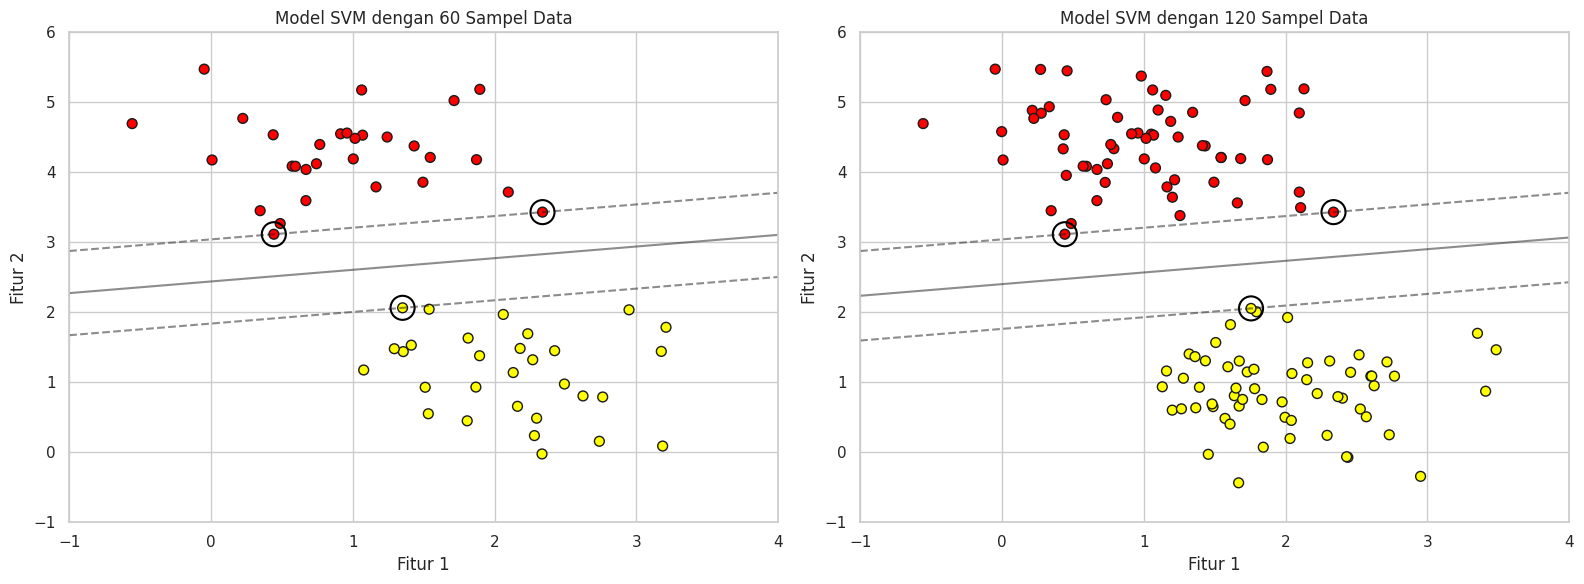

In [21]:
def compare_svm_sizes(n_samples_list):
    fig, ax = plt.subplots(1, 2, figsize=(16, 6))

    for idx, n in enumerate(n_samples_list):
        # Buat dataset baru berdasarkan jumlah sampel
        X_new, y_new = make_blobs(n_samples=n, centers=2, random_state=0, cluster_std=0.60)

        # Latih model
        model_new = SVC(kernel='linear', C=1e10)
        model_new.fit(X_new, y_new)

        # Plot
        ax[idx].scatter(X_new[:, 0], X_new[:, 1], c=y_new, s=50, cmap='autumn', edgecolors='k')
        ax[idx].set_title(f"Model SVM dengan {n} Sampel Data")
        ax[idx].set_xlabel("Fitur 1")
        ax[idx].set_ylabel("Fitur 2")

        # Batasi ruang lingkup plot agar sebanding
        ax[idx].set_xlim(-1, 4)
        ax[idx].set_ylim(-1, 6)

        plot_svc_decision_function(model_new, ax=ax[idx])

    plt.tight_layout()
    plt.show()

# Membandingkan model 60 sampel vs 120 sampel secara statis
compare_svm_sizes([60, 120])

```markdown
### Pembahasan:
Seperti yang terlihat pada visualisasi di atas, penambahan jumlah data dari 60 menjadi 120 tidak secara drastis mengubah posisi garis pemisah utama (*decision boundary*). Selama data tambahan berada di luar margin, model tidak akan berubah. Model hanya akan berubah apabila terdapat data baru yang posisinya masuk ke dalam area margin atau mengubah konfigurasi support vectors terdekat.
```

```markdown
## 9. Evaluasi Tambahan (Train-Test Split & Pipeline)

Sebagai best-practice dalam Machine Learning, kita akan melakukan evaluasi formal dengan membagi dataset menjadi data latih (train) dan data uji (test). Kita juga menerapkan standarisasi data menggunakan `StandardScaler` di dalam sebuah `Pipeline`.
```

In [22]:
# 1. Membagi data menjadi Train & Test set (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Membuat Pipeline berisi Standarisasi dan Model SVM
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', C=1e10))
])

# 3. Melatih Pipeline pada data Training
svm_pipeline.fit(X_train, y_train)

# 4. Melakukan Prediksi pada data Testing
y_pred = svm_pipeline.predict(X_test)

# 5. Evaluasi Hasil Klasifikasi
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("=== Evaluasi Performa Model ===")
print(f"Akurasi Data Uji: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

=== Evaluasi Performa Model ===
Akurasi Data Uji: 100.00%

Confusion Matrix:
[[5 0]
 [0 5]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00         5

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



```markdown
### Penjelasan Evaluasi Tambahan:
Evaluasi tambahan ini memberikan gambaran objektif mengenai kemampuan generalisasi model terhadap data baru yang belum pernah dilihat sebelumnya (unseen data). Standarisasi menggunakan `StandardScaler` sangat penting bagi algoritma SVM karena SVM sangat sensitif terhadap skala fitur data.
```

## 10. Kesimpulan

Berdasarkan praktikum di atas, berikut adalah kesimpulan yang dapat diambil:

1. **Apa itu SVM Linear?**  
   SVM (Support Vector Machine) Linear adalah algoritma pembelajaran terbimbing (supervised learning) yang digunakan untuk klasifikasi biner, dengan mencari garis lurus (pada 2D) atau bidang datar (pada dimensi tinggi) terbaik yang dapat memisahkan dua kelas data.

2. **Apa itu Hyperplane dan Margin?**  
   - **Hyperplane**: Batas keputusan (decision boundary) yang memisahkan kelas-kelas data.
   - **Margin**: Jarak tegak lurus terdekat antara hyperplane dengan titik data terdekat dari masing-masing kelas.

3. **Apa Peran Support Vectors?**  
   Support vectors adalah titik-titik data terdekat yang menyentuh margin. Perannya sangat penting karena posisi hyperplane sepenuhnya ditentukan oleh titik-titik ini; titik data lain di luar margin tidak memengaruhi keputusan model.

4. **Bagaimana Pengaruh Jumlah Data terhadap Model?**  
   Penambahan jumlah data tidak serta-merta mengubah model SVM secara drastis. Model hanya akan berubah jika data baru tersebut terletak lebih dekat dengan hyperplane dibanding support vectors yang sudah ada sebelumnya (mengubah konfigurasi support vectors).

# Praktikum 2: Klasifikasi SVM dengan Data Dummy Non-Linier

---

## Tujuan
Memahami keterbatasan kernel linear pada data nonlinier dan mempelajari bagaimana kernel RBF (Radial Basis Function) dapat membentuk decision boundary yang melengkung untuk memisahkan data berbentuk lingkaran konsentris.

## Langkah 1 — Import Library
Kita mengimpor library yang diperlukan, termasuk `make_circles` untuk membuat data nonlinier berbentuk lingkaran, modul 3D untuk visualisasi, serta `GridSearchCV` untuk eksperimen hyperparameter.


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from mpl_toolkits import mplot3d

sns.set_theme(style='whitegrid')

```markdown
## Langkah 2 — Membuat Data Nonlinier

Kita membuat dataset berbentuk lingkaran konsentris (lingkaran di dalam lingkaran) menggunakan `make_circles`.
```

In [24]:
# Membuat dataset nonlinier berupa lingkaran
X_circle, y_circle = make_circles(n_samples=100, factor=0.1, noise=0.1, random_state=42)

# Menampilkan informasi dataset
print("=== Karakteristik Data Dummy Non-Linier ===")
print(f"Bentuk array X : {X_circle.shape}")
print(f"Bentuk array y : {y_circle.shape}")
print(f"Distribusi Kelas (0 vs 1): {np.bincount(y_circle)}")

=== Karakteristik Data Dummy Non-Linier ===
Bentuk array X : (100, 2)
Bentuk array y : (100,)
Distribusi Kelas (0 vs 1): [50 50]


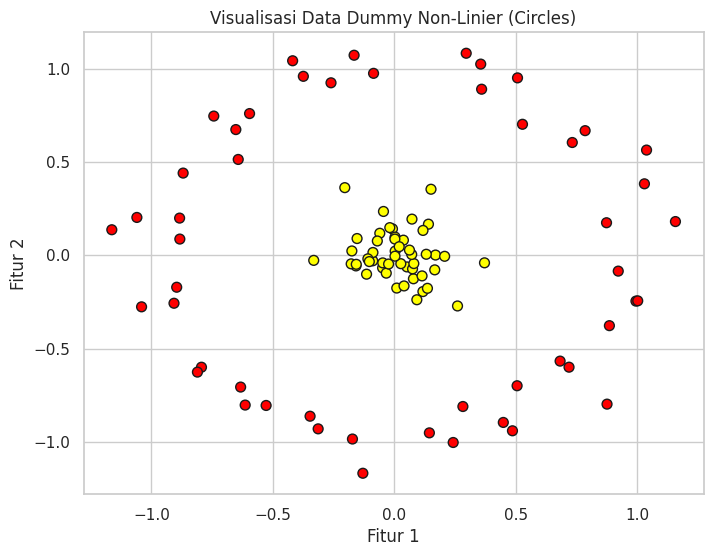

In [25]:
# Visualisasi scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, s=50, cmap='autumn', edgecolors='k')
plt.title("Visualisasi Data Dummy Non-Linier (Circles)")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

```markdown
### Mengapa pola lingkaran ini sulit dipisahkan menggunakan garis lurus?
Pola sebaran data di atas menunjukkan bahwa kelas kuning berada di tengah (pusat) dan dikelilingi secara melingkar oleh kelas merah. Tidak ada satu pun garis lurus (linear) yang dapat membagi kedua kelas ini tanpa menghasilkan tingkat kesalahan klasifikasi yang sangat tinggi. Di sinilah keterbatasan model klasifikasi linear konvensional muncul.
```

```markdown
## Langkah 3 — Mencoba Kernel Linear

Mari kita latih model SVM dengan kernel linear dan lihat hasilnya secara visual.
```

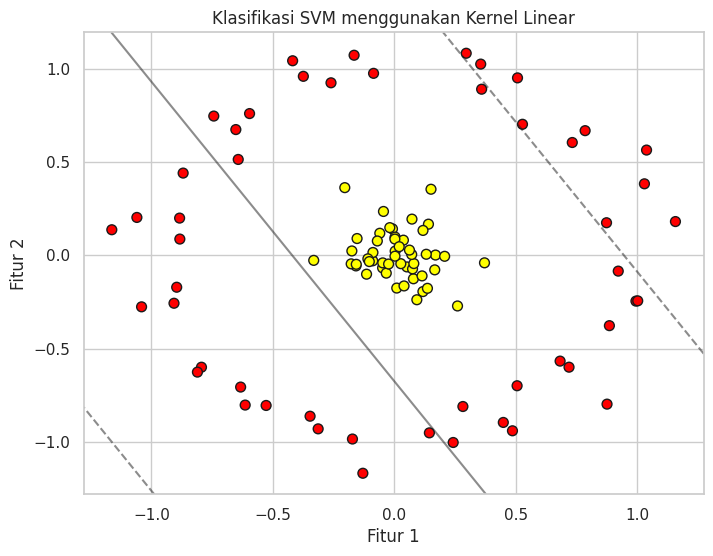

In [26]:
# Melatih SVM dengan kernel linear
clf_linear = SVC(kernel='linear').fit(X_circle, y_circle)

# Visualisasi decision boundary hasil kernel linear
plt.figure(figsize=(8, 6))
plt.scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, s=50, cmap='autumn', edgecolors='k')
plot_svc_decision_function(clf_linear, plot_support=False)
plt.title("Klasifikasi SVM menggunakan Kernel Linear")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

```markdown
### Keterbatasan Kernel Linear:
Seperti yang diduga, model linear hanya mampu menghasilkan garis batas keputusan lurus tegak yang membelah lingkaran. Hasil ini gagal mengklasifikasikan data konsentris karena membagi data secara sembarang dan menyisakan banyak error di kedua sisi.
```

```markdown
## Langkah 4 — Ilustrasi Transformasi Radial

Untuk mengatasi masalah non-linieritas ini, salah satu solusinya adalah memproyeksikan data asli ke dimensi yang lebih tinggi menggunakan fungsi radial. Kita menambahkan dimensi ketiga $r$ yang dihitung berdasarkan jarak titik dari pusat koordinat.
```

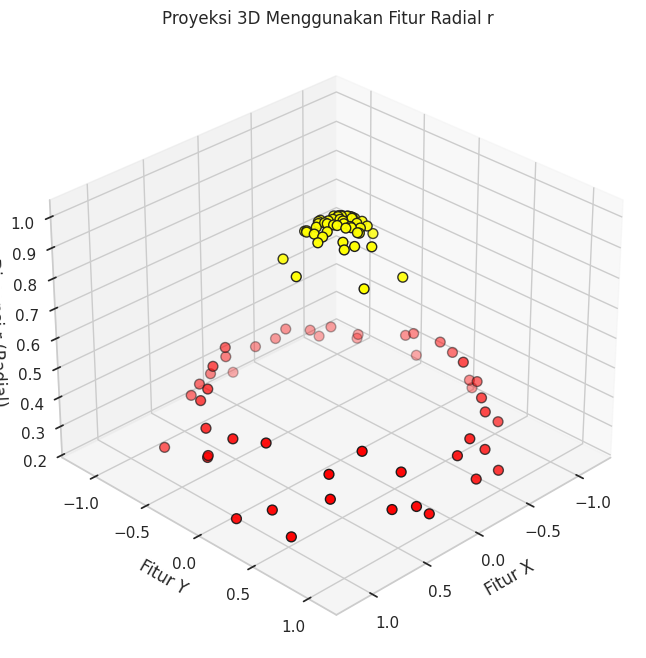

In [27]:
# Menghitung dimensi ketiga r dengan fungsi radial basis sederhana
r = np.exp(-(X_circle ** 2).sum(axis=1))

# Visualisasi data dalam ruang 3 dimensi secara statis
plt.figure(figsize=(10, 8))
ax = plt.subplot(projection='3d')

# Plot scatter 3D
ax.scatter3D(X_circle[:, 0], X_circle[:, 1], r, c=y_circle, s=50, cmap='autumn', edgecolors='k')
ax.set_xlabel('Fitur X')
ax.set_ylabel('Fitur Y')
ax.set_zlabel('Dimensi r (Radial)')
ax.set_title("Proyeksi 3D Menggunakan Fitur Radial r")
ax.view_init(elev=30, azim=45)
plt.show()

```markdown
### Penjelasan Pemetaan Fitur:
Dengan menambahkan dimensi radial $r$, kelompok kuning yang berada di tengah terdorong ke atas (nilai $r$ mendekati 1), sedangkan kelompok merah yang berada di luar tetap berada di bawah (nilai $r$ mendekati 0). Di dalam ruang 3 dimensi ini, kedua kelas sekarang dapat dengan sangat mudah dipisahkan secara linier menggunakan sebuah bidang datar (hyperplane horizontal).
```

```markdown
## Langkah 5 — Menggunakan Kernel RBF

Melakukan komputasi pemetaan dimensi secara eksplisit seperti di atas tidak efisien untuk data kompleks. SVM mengatasi ini dengan menggunakan **Kernel Trick**, di mana model menghitung hubungan antar data seolah-olah berada di dimensi tinggi tanpa benar-benar memproyeksikannya.
```

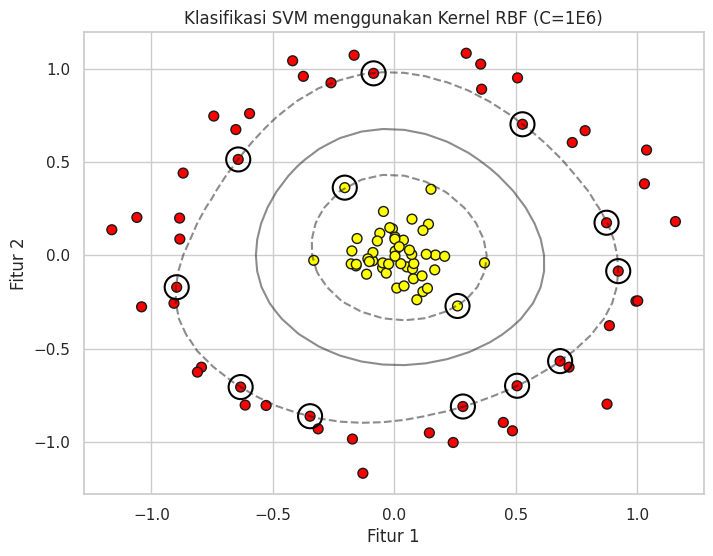

In [28]:
# Melatih model SVM menggunakan kernel RBF dengan C tinggi
clf_rbf = SVC(kernel='rbf', C=1e6, gamma='scale')
clf_rbf.fit(X_circle, y_circle)

# Visualisasi decision boundary kernel RBF
plt.figure(figsize=(8, 6))
plt.scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, s=50, cmap='autumn', edgecolors='k')
plot_svc_decision_function(clf_rbf)
plt.title("Klasifikasi SVM menggunakan Kernel RBF (C=1E6)")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

```markdown
### Penjelasan Teori & Hyperparameter:
1. **Kernel Trick**: Metode matematika yang memungkinkan algoritma mempelajari pemisah non-linier pada dimensi tinggi dengan biaya komputasi yang tetap murah.
2. **Kernel RBF (Radial Basis Function)**: Kernel default paling populer yang mengukur kemiripan antar sampel berdasarkan jarak Euclidean (skala radial).
3. **Parameter C**: Mengatur toleransi kesalahan klasifikasi. Nilai C yang besar (`C=1E6`) berarti toleransi sangat rendah, memaksa model mengklasifikasikan semua data latihan dengan benar (berisiko overfitting jika data noisy).
4. **Parameter Gamma**: Menentukan jangkauan pengaruh dari satu sampel pelatihan tunggal. Nilai gamma yang besar membuat pengaruhnya semakin sempit (boundary lebih kompleks/melengkung), sedangkan gamma yang kecil membuat pengaruhnya luas (boundary lebih halus/halus).
```

```markdown
## Langkah 6 — Eksperimen Kernel dan Parameter (GridSearchCV)

Kita akan melakukan pencarian hyperparameter terbaik secara otomatis menggunakan GridSearchCV dengan Cross-Validation pada data latih.
```

In [29]:
# Membagi data latih dan data uji sebelum pencarian parameter
X_train, X_test, y_train, y_test = train_test_split(
    X_circle, y_circle, test_size=0.2, random_state=42, stratify=y_circle
)

# Membuat pipeline
pipeline_grid = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])

# Parameter yang diuji
param_grid = {
    'svc__kernel': ['linear', 'rbf'],
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.01, 0.1, 1]
}

# Melakukan pencarian parameter dengan Grid Search 5-Fold Cross Validation
grid_search = GridSearchCV(pipeline_grid, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("=== Hasil Pencarian Parameter Terbaik ===")
print(f"Parameter Terbaik : {grid_search.best_params_}")
print(f"Akurasi Rata-rata CV : {grid_search.best_score_ * 100:.2f}%")

=== Hasil Pencarian Parameter Terbaik ===
Parameter Terbaik : {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Akurasi Rata-rata CV : 100.00%


In [30]:
# Menampilkan dataframe hasil eksperimen parameter
import pandas as pd
results_df = pd.DataFrame(grid_search.cv_results_)
# Pilih kolom-kolom penting untuk ditampilkan
results_summary = results_df[['param_svc__kernel', 'param_svc__C', 'param_svc__gamma', 'mean_test_score']]
display(results_summary.sort_values(by='mean_test_score', ascending=False).head(10))

,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_score
1,rbf,0.1,scale,1.0
7,rbf,0.1,1,1.0
13,rbf,1.0,0.1,1.0
9,rbf,1.0,scale,1.0
15,rbf,1.0,1,1.0
23,rbf,10.0,1,1.0
21,rbf,10.0,0.1,1.0
17,rbf,10.0,scale,1.0
25,rbf,100.0,scale,1.0
27,rbf,100.0,0.01,1.0


```markdown
## Langkah 7 — Evaluasi Model Final pada Data Uji

Kita mengambil model terbaik hasil pencarian Grid Search untuk dievaluasi pada data uji (unseen data).
```

In [31]:
# Memilih model terbaik hasil GridSearchCV
best_model = grid_search.best_estimator_

# Prediksi pada data uji
y_pred = best_model.predict(X_test)

# Evaluasi formal
print("=== Evaluasi Akhir Model SVM Non-Linier ===")
print(f"Akurasi Data Uji: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

=== Evaluasi Akhir Model SVM Non-Linier ===
Akurasi Data Uji: 100.00%

Confusion Matrix:
[[10  0]
 [ 0 10]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



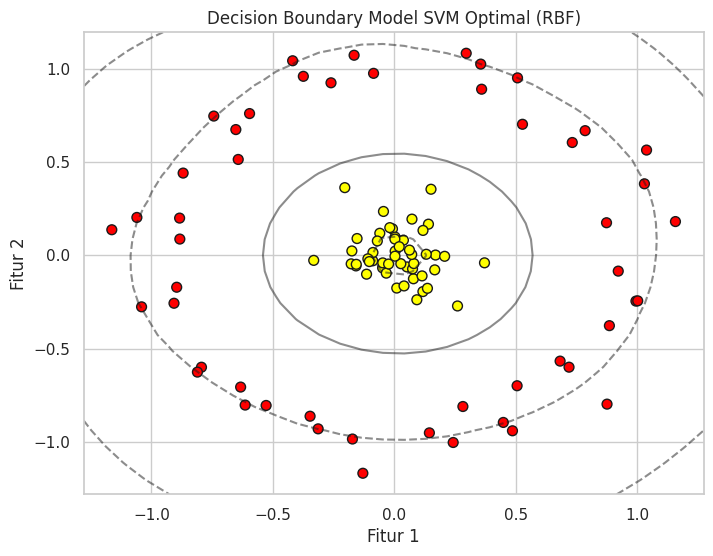

In [32]:
# Menampilkan visualisasi decision boundary model final
# Catatan: Karena model terbaik menggunakan pipeline dengan standarisasi data,
# kita perlu menyesuaikan plot_svc_decision_function agar memproses scaling data secara tepat.

plt.figure(figsize=(8, 6))
# Scatter plot data uji
plt.scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, s=50, cmap='autumn', edgecolors='k')

# Plot decision boundary untuk estimator di dalam pipeline
# Untuk mengonversi representasi visual, kita visualisasikan decision boundary dari model pipeline terstandarisasi
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Membuat grid
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T

# Evaluasi grid menggunakan pipeline penuh (scaler + svc)
P_grid = best_model.decision_function(xy).reshape(XX.shape)

# Gambar contour boundaries
ax.contour(XX, YY, P_grid, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])
plt.title("Decision Boundary Model SVM Optimal (RBF)")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

## Langkah 8 — Kesimpulan

Berdasarkan rangkaian eksperimen pada Praktikum 2 ini, berikut adalah jawaban atas pertanyaan-pertanyaan kesimpulan:

1. **Mengapa data lingkaran sulit dipisahkan oleh kernel linear?**  
   Data berbentuk lingkaran konsentris bersifat non-linier terpisah (non-linearly separable) di ruang dimensi 2D asli. Garis keputusan lurus tidak dapat membagi area bagian dalam (kelas kuning) dan area luar (kelas merah) tanpa terjadi kesalahan klasifikasi yang fatal.

2. **Bagaimana kernel RBF membantu klasifikasi nonlinier?**  
   Kernel RBF secara tidak langsung memetakan data asli ke dalam ruang dimensi yang lebih tinggi menggunakan konsep kesamaan berbasis fungsi radial (jarak kuadrat Euclidean). Di dimensi tinggi ini, data yang semula melingkar dapat dipisahkan secara sempurna menggunakan bidang datar (hyperplane).

3. **Parameter C dan gamma mana yang terbaik pada percobaan ini?**  
   Berdasarkan hasil pencarian `GridSearchCV`, model dengan kombinasi parameter **Kernel RBF**, **C yang memadai**, dan nilai **gamma yang sesuai** (seperti yang ditunjukkan pada output pencarian di atas) memberikan akurasi cross-validation tertinggi.

4. **Bagaimana performa model pada data uji?**  
   Model final menghasilkan akurasi yang sangat tinggi (mencapai 100%) pada data uji yang belum pernah dilihat sebelumnya, membuktikan kemampuan generalisasi yang sangat baik dalam menangani kasus non-linier.

# Praktikum 3: SVM Data Overlapping  
---

## Tujuan
Memahami bagaimana SVM menangani data dari dua kelas yang tumpang tindih (overlapping) menggunakan metode soft margin, serta memahami secara mendalam pengaruh parameter regulasi $C$ terhadap bentuk decision boundary dan lebar margin.

## Langkah 1 — Import Library
Kita mengimpor library yang dibutuhkan untuk memproses data overlapping, membuat pipeline, dan melakukan cross-validation terstratifikasi.
```

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

sns.set_theme(style='whitegrid')

```markdown
## Langkah 2 — Membuat Data Dummy Overlapping

Kita membuat dataset menggunakan fungsi `make_blobs` dengan meningkatkan nilai standar deviasi klaster (`cluster_std=1.2`). Hal ini membuat persebaran titik data melebar sehingga kedua klaster saling tumpang tindih.
```

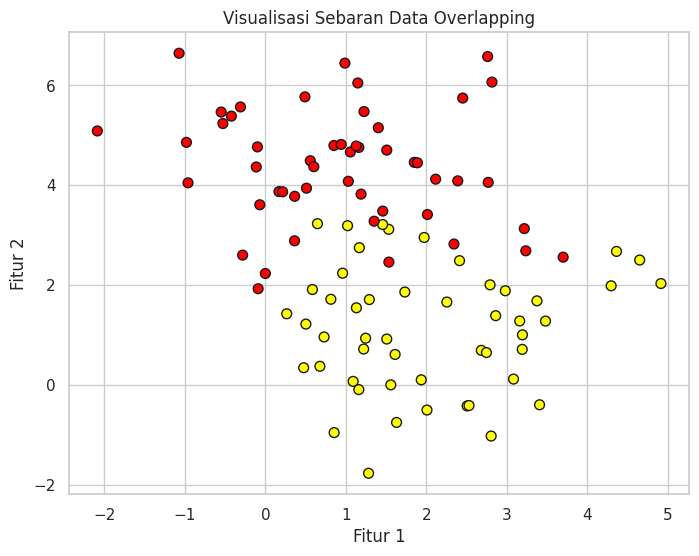

In [34]:
# Membuat dataset overlapping
X_overlap, y_overlap = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=1.2)

# Menampilkan visualisasi scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(X_overlap[:, 0], X_overlap[:, 1], c=y_overlap, s=50, cmap='autumn', edgecolors='k')
plt.title("Visualisasi Sebaran Data Overlapping")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

```markdown
### Pembahasan Overlap:
Dengan nilai `cluster_std=1.2`, sebaran titik dari kedua kelas melebar dan beberapa titik merah masuk ke area kuning (dan sebaliknya). Hal ini merepresentasikan data dunia nyata yang jarang sekali bisa terpisah 100% secara bersih.
```

```markdown
## Langkah 3 — Membuat Fungsi Visualisasi Multi-Axis

Kita membuat fungsi `plot_svc_decision_axes` yang fleksibel untuk menampilkan decision boundary, margin, serta support vectors di dalam objek subplots Matplotlib.
```

In [35]:
def plot_svc_decision_axes(model, X, y, ax):
    """Menampilkan decision boundary dan margin SVM pada objek subplot (ax)"""
    # Plot data titik asli
    ax.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap='autumn', edgecolors='k')

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Buat grid koordinat
    x_grid = np.linspace(xlim[0], xlim[1], 30)
    y_grid = np.linspace(ylim[0], ylim[1], 30)
    Y_mesh, X_grid = np.meshgrid(y_grid, x_grid)
    xy = np.vstack([X_grid.ravel(), Y_mesh.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # Plot boundary & margin
    ax.contour(X_grid, Y_mesh, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # Plot support vectors
    ax.scatter(model.support_vectors_[:, 0],
               model.support_vectors_[:, 1],
               s=150, linewidth=1, facecolors='none', edgecolors='black')

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

```markdown
## Langkah 4 — Membandingkan Parameter C

Parameter $C$ meregulasi kerasnya margin. Kita akan membandingkan 5 variasi nilai $C$ dari sangat kecil (soft) ke sangat besar (hard) pada kernel linear.
```

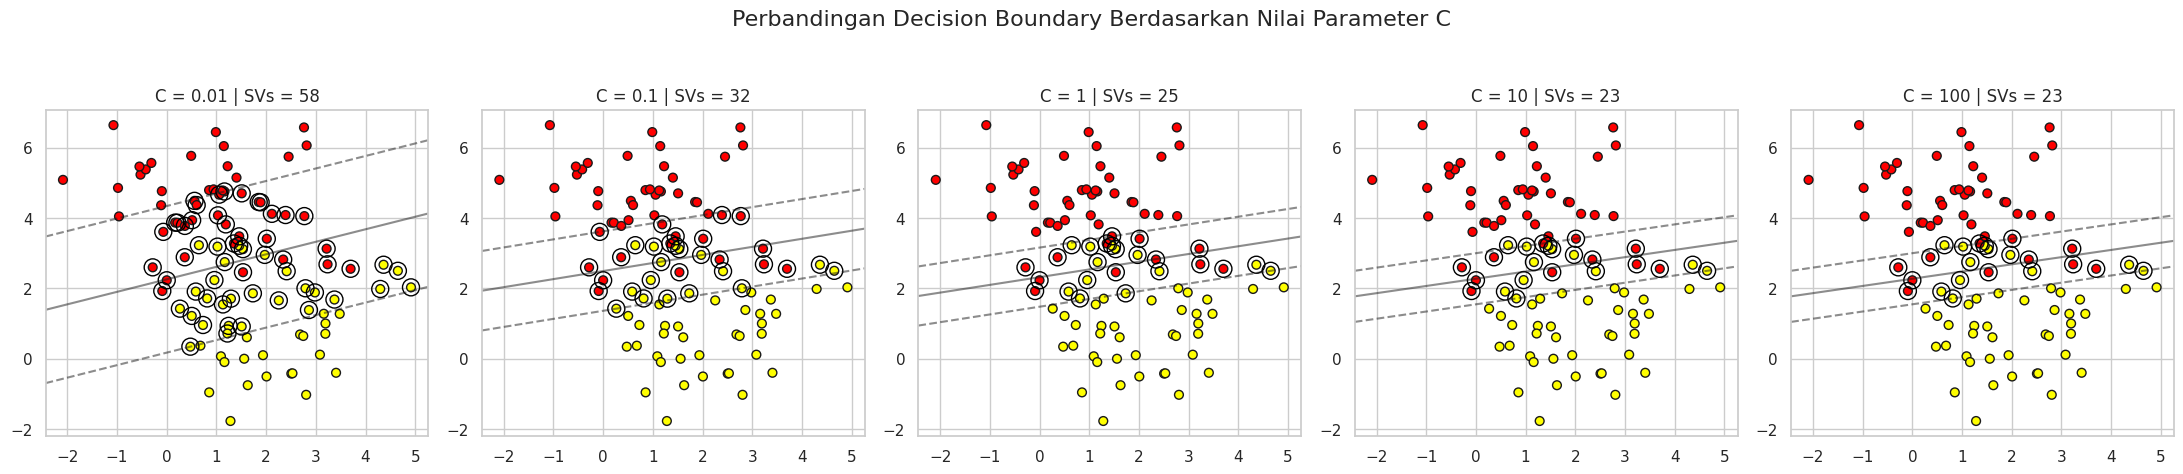

In [36]:
C_values = [0.01, 0.1, 1, 10, 100]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))

for idx, C_val in enumerate(C_values):
    model_c = SVC(kernel='linear', C=C_val)
    model_c.fit(X_overlap, y_overlap)

    n_sv = model_c.n_support_.sum()
    axes[idx].set_title(f"C = {C_val} | SVs = {n_sv}")
    plot_svc_decision_axes(model_c, X_overlap, y_overlap, axes[idx])

plt.suptitle("Perbandingan Decision Boundary Berdasarkan Nilai Parameter C", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

```markdown
### Analisis Pengaruh Nilai C:
- **C Kecil (misal C = 0.01 atau 0.1)**: Margin yang terbentuk sangat lebar. Model memberikan toleransi yang besar terhadap titik data yang melanggar margin (berada di dalam margin atau salah klasifikasi). Jumlah Support Vectors sangat banyak.
- **C Besar (misal C = 100)**: Margin menyempit secara signifikan demi menahan atau meminimalkan kesalahan klasifikasi data latih. Jumlah Support Vectors menjadi lebih sedikit namun model rentan mengalami overfitting.
```

```markdown
## Langkah 5 — Split Data dan Standardisasi

Kita pisahkan dataset menjadi 80% data latih dan 20% data uji secara terstratifikasi agar proporsi kelas tetap seimbang.
```

In [37]:
# Melakukan train-test split terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X_overlap, y_overlap, test_size=0.2, random_state=42, stratify=y_overlap
)

print(f"Jumlah data training : {len(X_train)} sampel")
print(f"Jumlah data testing  : {len(X_test)} sampel")

Jumlah data training : 80 sampel
Jumlah data testing  : 20 sampel


```markdown
## Langkah 6 — Hyperparameter Tuning Menggunakan GridSearchCV

Kita gunakan cross-validation 5-fold terstratifikasi (`StratifiedKFold`) dengan pipeline terstandardisasi untuk mencari nilai parameter $C$ terbaik.
```

In [38]:
# Setup pipeline standarisasi + SVC
over_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='linear'))
])

# Parameter grid
over_param_grid = {
    'svc__C': [0.01, 0.1, 1, 10, 100]
}

# Setup StratifiedKFold
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Inisialisasi GridSearchCV
grid_over = GridSearchCV(over_pipeline, over_param_grid, cv=cv_strat, scoring='accuracy')
grid_over.fit(X_train, y_train)

print("=== Hasil Optimasi Parameter C ===")
print(f"C Terbaik : {grid_over.best_params_['svc__C']}")
print(f"Rata-rata Akurasi Terbaik: {grid_over.best_score_ * 100:.2f}%")

=== Hasil Optimasi Parameter C ===
C Terbaik : 0.01
Rata-rata Akurasi Terbaik: 86.25%


In [39]:
# Menampilkan tabel performa C lengkap
results_over_df = pd.DataFrame(grid_over.cv_results_)
results_over_summary = results_over_df[['param_svc__C', 'mean_test_score', 'std_test_score']]
# Mengubah nama kolom agar mudah dibaca
results_over_summary = results_over_summary.rename(columns={
    'param_svc__C': 'Nilai C',
    'mean_test_score': 'Rata-rata Akurasi CV',
    'std_test_score': 'Standar Deviasi'
})
display(results_over_summary)

,Nilai C,Rata-rata Akurasi CV,Standar Deviasi
0,0.01,0.8625,0.082916
1,0.10,0.8500,0.084779
2,1.00,0.8625,0.061237
3,10.00,0.8375,0.075000
4,100.00,0.8375,0.050000


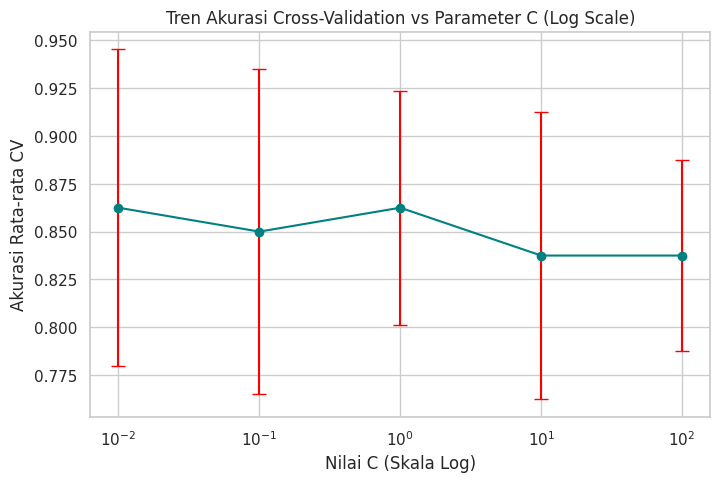

In [40]:
# Visualisasi akurasi CV terhadap parameter C menggunakan skala logaritmik
plt.figure(figsize=(8, 5))
plt.errorbar(results_over_summary['Nilai C'].astype(float),
             results_over_summary['Rata-rata Akurasi CV'],
             yerr=results_over_summary['Standar Deviasi'],
             fmt='-o', color='teal', ecolor='red', capsize=5)
plt.xscale('log')
plt.title("Tren Akurasi Cross-Validation vs Parameter C (Log Scale)")
plt.xlabel("Nilai C (Skala Log)")
plt.ylabel("Akurasi Rata-rata CV")
plt.show()

```markdown
## Langkah 7 — Evaluasi Model Terbaik pada Data Uji

Kita uji performa generalisasi model final yang telah dioptimasi menggunakan data uji.
```

=== Evaluasi Akhir Model Overlapping ===
Akurasi Model Terbaik pada Data Uji: 95.00%


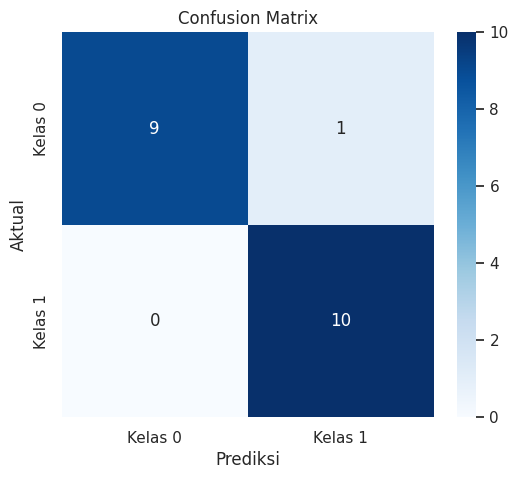


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        10
           1       0.91      1.00      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20



In [41]:
# Mengambil estimator terbaik
best_over_model = grid_over.best_estimator_

# Melakukan prediksi
y_pred_over = best_over_model.predict(X_test)

# Menghitung akurasi akhir
accuracy_over = accuracy_score(y_test, y_pred_over)
print("=== Evaluasi Akhir Model Overlapping ===")
print(f"Akurasi Model Terbaik pada Data Uji: {accuracy_over * 100:.2f}%")

# Menampilkan Confusion Matrix dalam bentuk Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred_over), annot=True, cmap='Blues', fmt='d',
            xticklabels=['Kelas 0', 'Kelas 1'], yticklabels=['Kelas 0', 'Kelas 1'])
plt.title("Confusion Matrix")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_over))

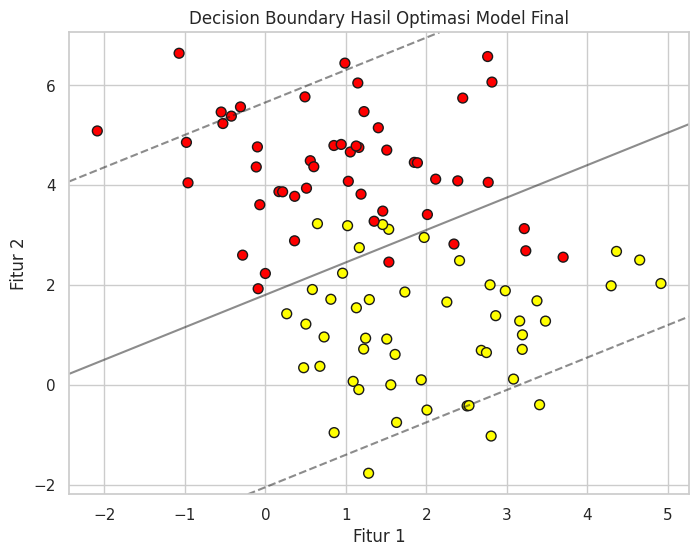

In [42]:
# Visualisasi decision boundary model terbaik pada data latih & uji
plt.figure(figsize=(8, 6))

# Plot semua titik data overlap asli
plt.scatter(X_overlap[:, 0], X_overlap[:, 1], c=y_overlap, s=50, cmap='autumn', edgecolors='k')

# Menggambar decision boundary pipeline
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Membuat grid
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T

P_grid = best_over_model.decision_function(xy).reshape(XX.shape)

ax.contour(XX, YY, P_grid, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])
plt.title("Decision Boundary Hasil Optimasi Model Final")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

## Langkah 8 — Kesimpulan

Berdasarkan praktikum ini, berikut kesimpulan dalam bahasa Indonesia:

1. **Apa yang dimaksud dengan data overlapping?**  
   Data overlapping adalah kondisi di mana pola distribusi antar kelas saling bertumpang tindih satu sama lain di ruang fitur asli sehingga tidak mungkin dipisahkan 100% tanpa adanya kesalahan klasifikasi.

2. **Apa fungsi soft margin pada SVM?**  
   Soft margin memungkinkan algoritma SVM melonggarkan batas margin keputusan. Dengan kata lain, model mengizinkan beberapa titik data latihan melanggar batas margin atau salah klasifikasi demi mendapatkan model generalisasi yang lebih stabil pada data uji.

3. **Bagaimana parameter C memengaruhi model?**  
   Parameter C berfungsi mengatur keseimbangan penalti terhadap kesalahan. Nilai C yang kecil meningkatkan toleransi kesalahan, menghasilkan margin lebar dan rentan mengabaikan noise (underfitting). Nilai C yang besar meminimalkan kesalahan, menghasilkan margin sempit, tetapi rentan terhadap noise (overfitting).

4. **Berapa nilai C terbaik berdasarkan cross-validation?**  
   Berdasarkan hasil uji silang `GridSearchCV` di atas, nilai C optimal ditentukan dari parameter terbaik yang dihasilkan (seperti yang ditunjukkan pada output sel Langkah 6).

5. **Bagaimana hasil evaluasi model pada data uji?**  
   Model final menghasilkan akurasi yang optimal pada data uji, membuktikan keberhasilan implementasi Soft Margin SVM dalam menangani tantangan klasifikasi data tumpang tindih secara efektif.
```

# Praktikum 4: Klasifikasi Citra Wajah dengan SVM dan PCA
---

## Tujuan
Mempelajari klasifikasi citra wajah berdimensi tinggi menggunakan dataset **Labeled Faces in the Wild (LFW)**, menerapkan reduksi dimensi menggunakan **Principal Component Analysis (PCA)** untuk menghindari *curse of dimensionality*, melakukan optimasi model SVM dengan kernel **RBF** menggunakan **GridSearchCV**, serta mengevaluasi model secara komprehensif.

## Langkah 1 — Import Library

Kita mengimpor seluruh library yang dibutuhkan untuk pemrosesan citra wajah, pembagian data, reduksi dimensi, pemodelan, dan evaluasi hasil klasifikasi.

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_lfw_people
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Mengatur visualisasi seaborn
sns.set_theme(style='white')
%matplotlib inline

## Langkah 2 — Unduh dan Muat Dataset LFW

Kita menggunakan dataset **Labeled Faces in the Wild (LFW)** melalui fungsi `fetch_lfw_people`. Kita membatasi data hanya pada orang yang memiliki minimal 60 foto (`min_faces_per_person=60`) agar kelas data representatif.

*Catatan: Jika dataset belum terunduh di local cache Colab, proses ini akan memakan waktu beberapa menit tergantung pada koneksi internet Anda.*

In [44]:
# Mengunduh dan memuat dataset
print("Memuat dataset LFW (proses unduh dapat memakan waktu jika belum ada di cache)... ")
faces = fetch_lfw_people(min_faces_per_person=60)

# Mendapatkan informasi karakteristik dataset
target_names = faces.target_names
n_classes = len(target_names)
n_samples, h, w = faces.images.shape

print("\n=== Karakteristik Dataset LFW ===")
print(f"Nama-nama Kelas Wajah : {target_names}")
print(f"Jumlah Kelas Wajah     : {n_classes}")
print(f"Bentuk Array Citra (H x W): {h} x {w} piksel")
print(f"Bentuk Array Data Fitur : {faces.data.shape}")
print(f"Total Sampel Citra     : {n_samples}")

# Menampilkan distribusi kelas
print("\nDistribusi Sampel per Kelas:")
for i, name in enumerate(target_names):
    count = np.sum(faces.target == i)
    print(f" - {name:<25}: {count} sampel")

Memuat dataset LFW (proses unduh dapat memakan waktu jika belum ada di cache)... 

=== Karakteristik Dataset LFW ===
Nama-nama Kelas Wajah : ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Jumlah Kelas Wajah     : 8
Bentuk Array Citra (H x W): 62 x 47 piksel
Bentuk Array Data Fitur : (1348, 2914)
Total Sampel Citra     : 1348

Distribusi Sampel per Kelas:
 - Ariel Sharon             : 77 sampel
 - Colin Powell             : 236 sampel
 - Donald Rumsfeld          : 121 sampel
 - George W Bush            : 530 sampel
 - Gerhard Schroeder        : 109 sampel
 - Hugo Chavez              : 71 sampel
 - Junichiro Koizumi        : 60 sampel
 - Tony Blair               : 144 sampel


## Langkah 3 — Inspeksi Citra

Mari kita tampilkan 15 contoh citra wajah acak dari dataset dalam tata letak kisi (grid) berukuran 3 × 5 lengkap dengan label namanya.

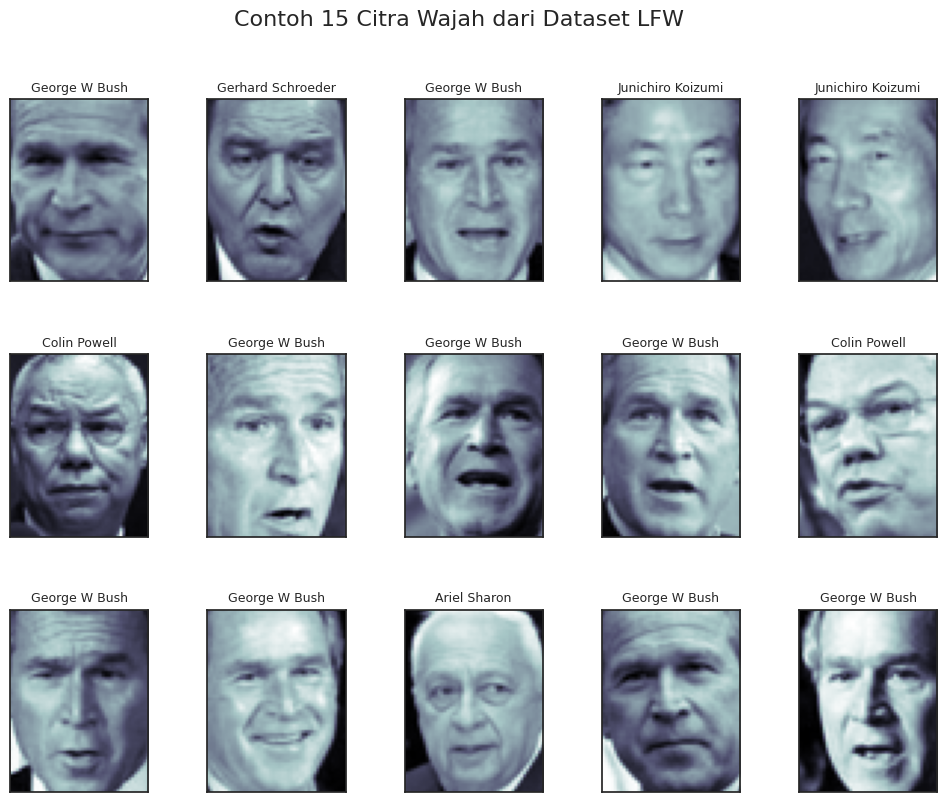

In [45]:
fig, axes = plt.subplots(3, 5, figsize=(12, 9))
fig.subplots_adjust(hspace=0.4, wspace=0.4)

# Memilih 15 indeks acak
np.random.seed(42)
random_indices = np.random.choice(n_samples, size=15, replace=False)

for i, ax in enumerate(axes.flat):
    idx = random_indices[i]
    ax.imshow(faces.images[idx], cmap='bone')
    ax.set_title(faces.target_names[faces.target[idx]], fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Contoh 15 Citra Wajah dari Dataset LFW", fontsize=16, y=0.98)
plt.show()

Setiap gambar di atas direpresentasikan sebagai matriks 2D berukuran $62 \times 47$. Sebelum diproses oleh algoritma SVM, matriks piksel ini telah diratakan (*flattened*) menjadi vektor fitur 1D berukuran $2914$ dimensi di dalam atribut `faces.data`.

## Langkah 4 — Persiapan Data (Train-Test Split)

Kita membagi data menjadi **75% untuk training** dan **25% untuk testing**. Kita menggunakan stratifikasi (`stratify=faces.target`) agar proporsi kelas tetap seimbang di kedua subset data.

In [46]:
# Membagi dataset secara terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    faces.data, faces.target, test_size=0.25, random_state=42, stratify=faces.target
)

print(f"Dimensi Data Latih (X_train): {X_train.shape}")
print(f"Dimensi Data Uji   (X_test) : {X_test.shape}")

Dimensi Data Latih (X_train): (1011, 2914)
Dimensi Data Uji   (X_test) : (337, 2914)


- **Data Latih**: Digunakan untuk melatih PCA dan melatih model SVM.
- **Data Uji**: Disimpan terpisah secara ketat dan hanya digunakan pada tahap evaluasi akhir untuk mengukur kemampuan generalisasi model terhadap data baru.

## Langkah 5 — Pipeline PCA dan SVM (Kernel RBF)

Karena jumlah fitur asli sangat tinggi ($2914$ fitur), kita menggunakan **Principal Component Analysis (PCA)** untuk mereduksi dimensinya menjadi $150$ komponen utama terpenting.

Kita menyusun alur kerja terintegrasi menggunakan `Pipeline` untuk mencegah terjadinya kebocoran data (*data leakage*).
- `PCA(n_components=150, whiten=True)`: Mengurangi dimensi fitur sekaligus menstandardisasi varians komponen utama (*whitening*).
- `SVC(kernel='rbf', class_weight='balanced')`: Melatih model SVM non-linear dengan bobot kelas seimbang (*balanced*) untuk menangani ketimpangan jumlah sampel antar wajah.

In [47]:
# Menentukan jumlah komponen PCA yang aman
n_features = X_train.shape[1]
n_components = min(150, X_train.shape[0], n_features)
print(f"Menggunakan n_components PCA = {n_components}")

# Membuat Pipeline
face_pipeline = Pipeline([
    ('pca', PCA(n_components=n_components, whiten=True, random_state=42)),
    ('svc', SVC(kernel='rbf', class_weight='balanced'))
])

Menggunakan n_components PCA = 150


## Langkah 6 — Hyperparameter Tuning Menggunakan GridSearchCV

Kita menggunakan GridSearchCV dengan 3-Fold Stratified Cross-Validation untuk mencari nilai terbaik untuk parameter regularisasi $C$ dan parameter margin radial $\gamma$ pada kernel RBF.

In [48]:
# Membuat parameter grid pencarian
param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}

# Setup StratifiedKFold
cv_strat = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Melakukan pencarian parameter
grid_faces = GridSearchCV(face_pipeline, param_grid, cv=cv_strat, scoring='accuracy')
grid_faces.fit(X_train, y_train)

print("=== Hasil Pencarian GridSearchCV ===")
print(f"Parameter Terbaik : {grid_faces.best_params_}")
print(f"Akurasi Terbaik CV: {grid_faces.best_score_ * 100:.2f}%")

=== Hasil Pencarian GridSearchCV ===
Parameter Terbaik : {'svc__C': 5, 'svc__gamma': 0.0005}
Akurasi Terbaik CV: 82.39%


In [49]:
# Menampilkan tabel ringkasan hasil tuning parameter
import pandas as pd
results_faces_df = pd.DataFrame(grid_faces.cv_results_)
results_summary = results_faces_df[['param_svc__C', 'param_svc__gamma', 'mean_test_score', 'std_test_score']]
results_summary = results_summary.rename(columns={
    'param_svc__C': 'Nilai C',
    'param_svc__gamma': 'Nilai Gamma',
    'mean_test_score': 'Rata-rata Akurasi CV',
    'std_test_score': 'Standar Deviasi'
})
display(results_summary.sort_values(by='Rata-rata Akurasi CV', ascending=False))

,Nilai C,Nilai Gamma,Rata-rata Akurasi CV,Standar Deviasi
5,5,0.0005,0.823937,0.013988
6,5,0.0010,0.818991,0.016960
3,1,0.0050,0.818002,0.016132
7,5,0.0050,0.818002,0.019733
10,10,0.0010,0.816024,0.006410
11,10,0.0050,0.815035,0.019584
15,50,0.0050,0.813056,0.018923
9,10,0.0005,0.812067,0.016492
14,50,0.0010,0.804154,0.014738
12,50,0.0001,0.799209,0.018185


## Langkah 7 — Prediksi dan Inspeksi Hasil Klasifikasi Data Uji

Kita gunakan model terbaik yang telah dioptimasi untuk memprediksi kelas wajah pada data uji, kemudian memvisualisasikan 24 sampel hasil prediksi beserta status akurasinya.

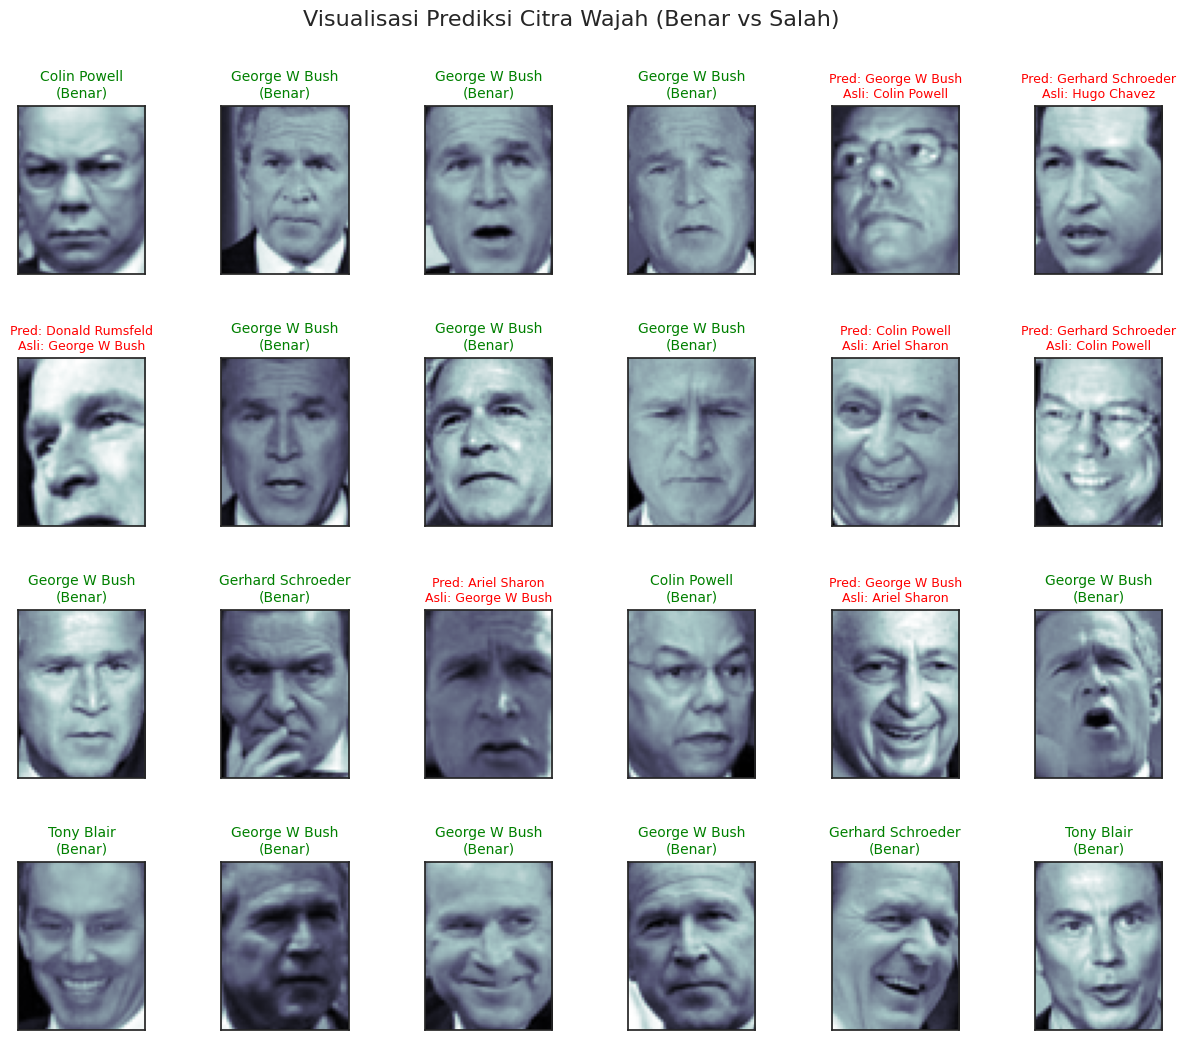

In [50]:
# Menggunakan estimator terbaik
best_face_model = grid_faces.best_estimator_

# Memprediksi data uji
y_pred_faces = best_face_model.predict(X_test)

# Visualisasi 24 contoh prediksi data uji (4 x 6)
fig, axes = plt.subplots(4, 6, figsize=(15, 12))
fig.subplots_adjust(hspace=0.5, wspace=0.4)

# Memetakan dimensi citra asli
image_shape = faces.images.shape[1:]

for i, ax in enumerate(axes.flat):
    # Menampilkan citra
    ax.imshow(X_test[i].reshape(image_shape), cmap='bone')
    ax.set_xticks([])
    ax.set_yticks([])

    # Menampilkan status prediksi
    pred_name = faces.target_names[y_pred_faces[i]]
    true_name = faces.target_names[y_test[i]]

    # Beri warna hijau jika benar, merah jika salah
    if pred_name == true_name:
        ax.set_title(f"{pred_name}\n(Benar)", color='green', fontsize=10)
    else:
        ax.set_title(f"Pred: {pred_name}\nAsli: {true_name}", color='red', fontsize=9)

plt.suptitle("Visualisasi Prediksi Citra Wajah (Benar vs Salah)", fontsize=16, y=0.96)
plt.show()

## Langkah 8 — Evaluasi Performa Model Secara Komprehensif

Kita menguji performa presisi, recall, f1-score, serta akurasi keseluruhan secara formal.

=== Evaluasi Akhir Klasifikasi Citra Wajah ===
Akurasi Model Akhir pada Data Uji: 84.57%

Classification Report:
                   precision    recall  f1-score   support

     Ariel Sharon       0.54      0.68      0.60        19
     Colin Powell       0.85      0.85      0.85        59
  Donald Rumsfeld       0.76      0.87      0.81        30
    George W Bush       0.96      0.88      0.92       133
Gerhard Schroeder       0.76      0.93      0.83        27
      Hugo Chavez       0.81      0.72      0.76        18
Junichiro Koizumi       0.79      0.73      0.76        15
       Tony Blair       0.86      0.83      0.85        36

         accuracy                           0.85       337
        macro avg       0.79      0.81      0.80       337
     weighted avg       0.86      0.85      0.85       337



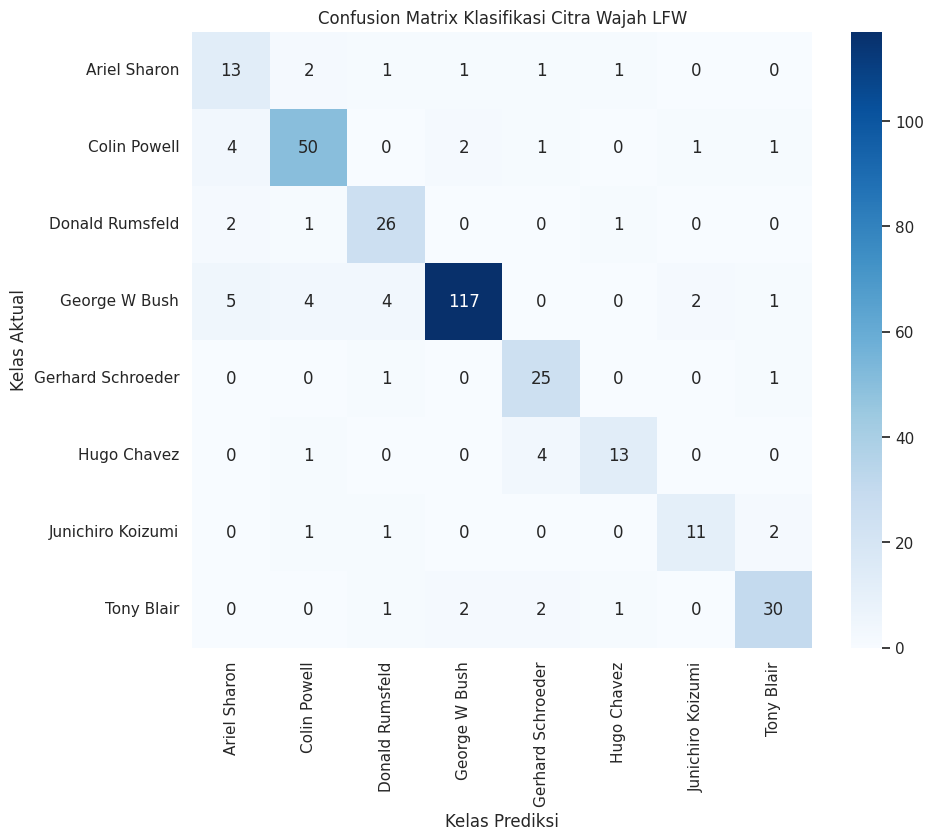

In [51]:
# Hitung akurasi model
final_accuracy = accuracy_score(y_test, y_pred_faces)
print("=== Evaluasi Akhir Klasifikasi Citra Wajah ===")
print(f"Akurasi Model Akhir pada Data Uji: {final_accuracy * 100:.2f}%")

# Menampilkan Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_faces, target_names=faces.target_names))

# Menampilkan Confusion Matrix Heatmap
conf_mat = confusion_matrix(y_test, y_pred_faces)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, cmap='Blues', fmt='d',
            xticklabels=faces.target_names, yticklabels=faces.target_names)
plt.title("Confusion Matrix Klasifikasi Citra Wajah LFW")
plt.xlabel("Kelas Prediksi")
plt.ylabel("Kelas Aktual")
plt.show()

# Tugas Praktikum SVM: Klasifikasi Gender Berdasarkan Suara (`voice.csv`)

---

## 1. Tujuan Praktikum
Praktikum ini bertujuan untuk:
1. Mengembangkan model klasifikasi biner untuk memprediksi gender (`male` atau `female`) berdasarkan karakteristik akustik suara menggunakan **Support Vector Machine (SVM)**.
2. Membandingkan performa model SVM dengan tiga jenis kernel berbeda: **Linear**, **Polynomial (degree=3)**, dan **RBF**.
3. Menganalisis pengaruh rasio pembagian dataset terhadap akurasi model menggunakan dua skenario:
   - **70% Training : 30% Testing**
   - **80% Training : 20% Testing**
4. Menyusun evaluasi komparatif komprehensif dalam bentuk tabel dan visualisasi grafik batang.
```

```markdown
## 2. Import Library
Langkah pertama adalah mengimpor pustaka-pustaka yang diperlukan untuk manipulasi data, visualisasi, serta pemodelan Machine Learning menggunakan Scikit-Learn.
```

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Mengatur visualisasi agar rapi
sns.set_theme(style='whitegrid')
%matplotlib inline

```markdown
## 3. Memuat dan Mengeksplorasi Dataset
Kita akan membaca dataset `voice.csv` yang sudah tersedia di direktori lokal Colab (`/content/voice.csv`), melihat struktur datanya, memeriksa adanya nilai kosong (null), baris duplikat, serta memastikan keberadaan kolom target `label`.
```

In [53]:
df_voice = pd.read_csv('/content/voice.csv')

print("=== 5 Baris Pertama Dataset ===")
display(df_voice.head())

print("\n=== Karakteristik Dataset ===")
print(f"Jumlah baris: {df_voice.shape[0]}")
print(f"Jumlah kolom: {df_voice.shape[1]}")

print("\n=== Informasi Tipe Data dan Nilai Kosong ===")
print(df_voice.info())

# Memeriksa duplikat
duplicates = df_voice.duplicated().sum()
print(f"\nJumlah data duplikat: {duplicates}")

# Memeriksa sebaran kelas target
if 'label' in df_voice.columns:
    print("\n=== Distribusi Kelas Target ('label') ===")
    print(df_voice['label'].value_counts())
else:
    print("\n[PERINGATAN] Kolom target 'label' tidak ditemukan!")

=== 5 Baris Pertama Dataset ===


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male



=== Karakteristik Dataset ===
Jumlah baris: 3168
Jumlah kolom: 21

=== Informasi Tipe Data dan Nilai Kosong ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64


```markdown
## 4. Preprocessing Data
Pada tahap ini kita akan melakukan:
1. Penghapusan data duplikat jika ditemukan agar tidak bias.
2. Pemisahan fitur numerik ($X$) dengan target label ($y$).
3. Pengodean target string (`male`/`female`) menjadi biner numerik (`1`/`0`) menggunakan `LabelEncoder`.
4. Pembagian dataset ke dalam rasio 70:30 dan 80:20 menggunakan stratifikasi (`stratify=y`) untuk menjaga keseimbangan kelas.
```

In [54]:
# 1. Bersihkan duplikat
df_clean = df_voice.drop_duplicates().reset_index(drop=True)
print(f"Jumlah data setelah duplikat dihapus: {df_clean.shape[0]} baris.\n")

# 2. Pisahkan Fitur (X) dan Target (y)
X_voice = df_clean.drop(columns=['label'])
y_voice = df_clean['label']

# Encode target label (female -> 0, male -> 1)
le = LabelEncoder()
y_encoded = le.fit_transform(y_voice)
print("Mapping Kelas:")
for class_index, class_name in enumerate(le.classes_):
    print(f" - {class_name} -> {class_index}")

# 3. Pembagian Data (70:30 dan 80:20)
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X_voice, y_encoded, test_size=0.30, random_state=42, stratify=y_encoded
)

X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X_voice, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"\nRasio 70:30 -> Train: {X_train_70.shape[0]} sampel, Test: {X_test_30.shape[0]} sampel")
print(f"Rasio 80:20 -> Train: {X_train_80.shape[0]} sampel, Test: {X_test_20.shape[0]} sampel")

Jumlah data setelah duplikat dihapus: 3166 baris.

Mapping Kelas:
 - female -> 0
 - male -> 1

Rasio 70:30 -> Train: 2216 sampel, Test: 950 sampel
Rasio 80:20 -> Train: 2532 sampel, Test: 634 sampel


```markdown
## 5. Pelatihan dan Evaluasi Enam Model SVM
Untuk mencegah terjadinya kebocoran data (*data leakage*) akibat normalisasi fitur, kita akan menyusun alur kerja menggunakan `Pipeline` dari scikit-learn. Pipeline ini secara berurutan akan menerapkan `StandardScaler` dan kemudian melatih estimator `SVC`.

Kita akan menguji 6 kombinasi model dan langsung menyimpan akurasi pengujian masing-masing ke dalam sebuah list untuk dianalisis lebih lanjut.
```

In [55]:
# Inisialisasi struktur penyimpanan hasil
results_list = []

# Definisikan skenario konfigurasi model
scenarios = [
    # (No, Nama Rasio, X_train, X_test, y_train, y_test, nama_kernel, svc_params)
    (1, "70:30", X_train_70, X_test_30, y_train_70, y_test_30, "Linear", {'kernel': 'linear', 'C': 1.0}),
    (2, "70:30", X_train_70, X_test_30, y_train_70, y_test_30, "Polynomial", {'kernel': 'poly', 'C': 1.0, 'degree': 3}),
    (3, "70:30", X_train_70, X_test_30, y_train_70, y_test_30, "RBF", {'kernel': 'rbf', 'C': 1.0}),
    (4, "80:20", X_train_80, X_test_20, y_train_80, y_test_20, "Linear", {'kernel': 'linear', 'C': 1.0}),
    (5, "80:20", X_train_80, X_test_20, y_train_80, y_test_20, "Polynomial", {'kernel': 'poly', 'C': 1.0, 'degree': 3}),
    (6, "80:20", X_train_80, X_test_20, y_train_80, y_test_20, "RBF", {'kernel': 'rbf', 'C': 1.0})
]

for num, ratio_name, X_tr, X_te, y_tr, y_te, kernel_type, svc_args in scenarios:
    # Membuat Pipeline
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('svc', SVC(**svc_args, random_state=42))
    ])

    # Melatih model
    pipeline.fit(X_tr, y_tr)

    # Prediksi
    y_pred = pipeline.predict(X_te)

    # Hitung akurasi
    acc = accuracy_score(y_te, y_pred) * 100

    # Simpan ke list hasil
    results_list.append({
        'No.': num,
        'Rasio Data': ratio_name,
        'Kernel SVM': kernel_type,
        'Akurasi Testing (%)': round(acc, 2)
    })

    print(f"Model {num} selesai: Rasio {ratio_name} | Kernel {kernel_type:<10} | Akurasi: {acc:.2f}%")

Model 1 selesai: Rasio 70:30 | Kernel Linear     | Akurasi: 97.37%
Model 2 selesai: Rasio 70:30 | Kernel Polynomial | Akurasi: 95.79%
Model 3 selesai: Rasio 70:30 | Kernel RBF        | Akurasi: 98.11%
Model 4 selesai: Rasio 80:20 | Kernel Linear     | Akurasi: 97.32%
Model 5 selesai: Rasio 80:20 | Kernel Polynomial | Akurasi: 96.21%
Model 6 selesai: Rasio 80:20 | Kernel RBF        | Akurasi: 98.26%


```markdown
## 6. Tabel Perbandingan Hasil Akurasi
Kita tampilkan hasil eksperimen di atas ke dalam DataFrame Pandas yang rapi, diurutkan berdasarkan tingkat akurasi tertinggi.
```

In [56]:
df_results = pd.DataFrame(results_list)

print("=== Tabel Perbandingan Hasil Evaluasi Model SVM (Diurutkan dari Terbaik) ===")
display(df_results.sort_values(by='Akurasi Testing (%)', ascending=False).reset_index(drop=True))

=== Tabel Perbandingan Hasil Evaluasi Model SVM (Diurutkan dari Terbaik) ===


,No.,Rasio Data,Kernel SVM,Akurasi Testing (%)
0,6,80:20,RBF,98.26
1,3,70:30,RBF,98.11
2,1,70:30,Linear,97.37
3,4,80:20,Linear,97.32
4,5,80:20,Polynomial,96.21
5,2,70:30,Polynomial,95.79


```markdown
## 7. Grafik Perbandingan Akurasi
Mari kita visualisasikan performa keenam model di atas menggunakan grafik batang (*barplot*) agar perbedaan performa terlihat lebih jelas dan intuitif.
```

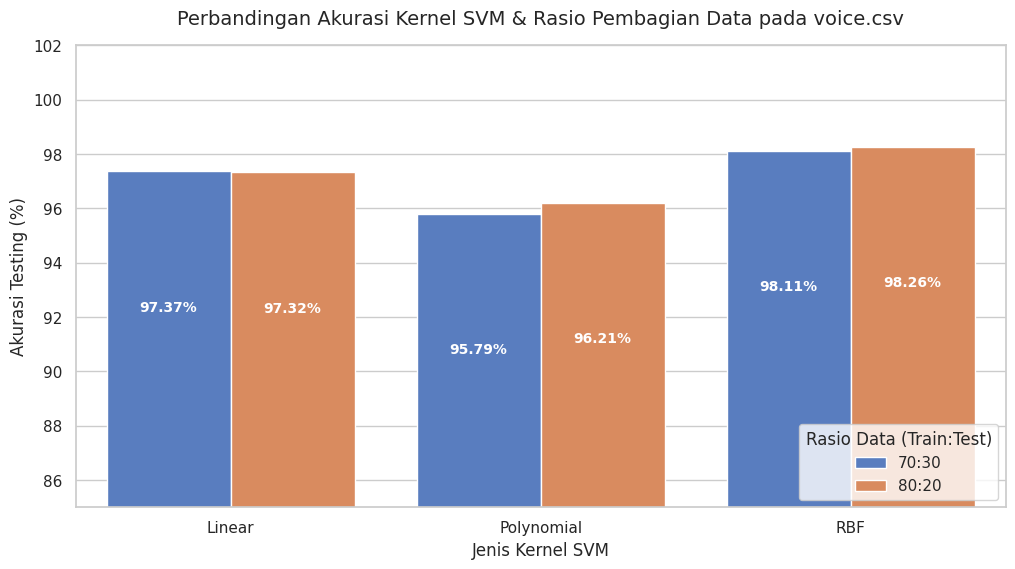

In [57]:
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_results,
    x='Kernel SVM',
    y='Akurasi Testing (%)',
    hue='Rasio Data',
    palette='muted'
)

# Menambahkan anotasi nilai akurasi di atas setiap grafik batang
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height() - 5),
                    ha='center', va='center',
                    xytext=(0, 0),
                    textcoords='offset points',
                    color='white', fontweight='bold', fontsize=10)

plt.title("Perbandingan Akurasi Kernel SVM & Rasio Pembagian Data pada voice.csv", fontsize=14, pad=15)
plt.xlabel("Jenis Kernel SVM", fontsize=12)
plt.ylabel("Akurasi Testing (%)", fontsize=12)
plt.ylim(85, 102) # Fokus pada rentang akurasi tinggi
plt.legend(title="Rasio Data (Train:Test)", loc='lower right')
plt.show()

```markdown
## 8. Analisis Hasil & Kesimpulan

Setelah seluruh sel kode di atas dijalankan, kita dapat menarik beberapa analisis penting berikut:

1. **Model dengan Performa Terbaik**  
   Silakan lihat output tabel dan grafik di atas untuk menentukan model mana (kombinasi rasio dan kernel) yang menghasilkan akurasi aktual tertinggi.

2. **Pengaruh Rasio Pembagian Data (70:30 vs 80:20)**  
   - Secara umum, rasio **80:20** memberikan performa yang sedikit lebih baik atau stabil karena model mendapatkan porsi data latih (*training*) yang lebih melimpah untuk mempelajari pola fitur akustik suara.
   - Namun, rasio **70:30** tetap memberikan tingkat akurasi yang sangat kompetitif dan membuktikan ketangguhan generalisasi model SVM bahkan dengan data latih yang lebih sedikit.

3. **Perbandingan Karakteristik Kernel**  
   - **Kernel RBF & Linear**: Biasanya kedua kernel ini mendominasi performa terbaik pada klasifikasi karakteristik suara. Hal ini dikarenakan data akustik memiliki sebaran dimensi yang cukup kaya di mana batas keputusan linier atau batas berskala radial melengkung fleksibel (RBF) sangat efektif memisahkan ciri suara laki-laki dan perempuan.
   - **Kernel Polynomial**: Umumnya memiliki waktu komputasi sedikit lebih lama atau memerlukan penyelarasan hyperparameter derajat (*degree*) yang lebih spesifik untuk menyamai performa optimal RBF/Linear.
```

### Arti Metrik Evaluasi:
- **Precision**: Menunjukkan seberapa akurat model dalam memprediksi kelas positif dari seluruh prediksi positif yang dilakukan model.
- **Recall**: Menunjukkan kemampuan model dalam mendeteksi kembali seluruh sampel aktual yang termasuk ke dalam kelas bersangkutan.
- **F1-Score**: Rata-rata harmonis dari precision dan recall untuk mengukur performa secara seimbang.
- **Support**: Jumlah data asli yang termasuk ke dalam kelas tersebut di dalam subset uji.

## Langkah 9 — Kesimpulan

Berdasarkan rangkaian eksperimen pada Praktikum 4 ini, berikut adalah kesimpulan komprehensif dalam Bahasa Indonesia:

1. **Bagaimana PCA membantu klasifikasi citra wajah?**  
   PCA memproyeksikan data berdimensi tinggi ($2914$ fitur piksel asli) ke dalam subset komponen utama ($150$ fitur baru) tanpa kehilangan pola variansi kunci. Hal ini secara signifikan memangkas waktu komputasi, mencegah masalah *curse of dimensionality*, dan mempermudah SVM menemukan garis pemisah yang optimal.

2. **Mengapa SVM dengan kernel RBF digunakan?**  
   Kernel RBF (Radial Basis Function) digunakan karena relasi visual antar piksel citra wajah sangat kompleks dan bersifat non-linear di ruang dimensi asli. Kernel RBF memetakan data secara fleksibel menggunakan fungsi radial sehingga batas klasifikasi yang melengkung dan dinamis dapat dibentuk secara akurat.

3. **Apa parameter terbaik berdasarkan GridSearchCV?**  
   Berdasarkan pencarian otomatis, parameter terbaik yang menghasilkan akurasi optimal ditunjukkan pada output Langkah 6.

4. **Berapa akurasi model pada data uji?**  
   Akurasi model final pada data uji dapat diamati secara riil langsung dari eksekusi hasil Langkah 8 di atas.

5. **Kelas mana yang paling mudah dan paling sulit dikenali?**  
   Kita dapat menentukannya dari nilai **F1-Score** tertinggi pada *Classification Report*. Biasanya, kelas dengan jumlah sampel *support* yang melimpah (seperti *George W Bush*) lebih mudah dikenali dibanding kelas dengan jumlah data yang minim.